# EDA - Analisi Esplorativa dei Dataset

In questo notebook andremo ad analizzare i seguenti datasets:

- KANDY-EASY
- KANDY-HARD
- KANDY-BONGARD
- BONGARD-RWR+

Quello che vogliamo verificare è:

- struttura dei dataset;
- distribuzione dei task;
- bilanciamento delle etichette;
- esempi presenti;
- eventuali annotazioni simboliche;
- concetti visivi presenti.

## Librerie Necessarie

In [3]:
%pip install pandas matplotlib pillow pyyaml


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /home/cosimo/Downloads/kandy-xai/.venv/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## KANDY-EASY

In [4]:
from pathlib import Path
#mi permette di gestire più agilmente i percorsi
from collections import Counter
#mi permette di contare quante volte un elemento compare in una sequenza
import ast
#permette di trasformate una stringa di dati in una struttura dati di python
#es.: "[1,2,3]" -> [1, 2, 3]
import pandas as pd
import pandas as pd
import pandas as pd
#pandas per gestione dati tabellari
import matplotlib.pyplot as plt
#matplotlib per grafici
from PIL import Image
#pillow per lavorare con le immagini


PROJECT_ROOT = Path.cwd().parent
#ottengo la cartella di lavoro corrente

DATA_DIR = PROJECT_ROOT / "data" / "easy" / "samples" / "sets"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

TRAIN_CSV = TRAIN_DIR / "annotations.csv"
VAL_CSV = VAL_DIR / "annotations.csv"
TEST_CSV = TEST_DIR / "annotations.csv"
#creo i vari percorsi/file in cui salvare i risultati

RESULTS_DIR = PROJECT_ROOT / "results"
PLOTS_DIR = RESULTS_DIR / "dataset_exploration"
PLOTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
#crea la cartella in cui salviamo tutti i risultati del notebook

print("Project root:", PROJECT_ROOT)
print("Train directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)


Project root: /home/cosimo/progetti/tesi
Train directory: /home/cosimo/progetti/tesi/data/easy/samples/sets/train
Validation directory: /home/cosimo/progetti/tesi/data/easy/samples/sets/val
Test directory: /home/cosimo/progetti/tesi/data/easy/samples/sets/test


### Caricamento delle annotazioni

In [5]:
df_train = pd.read_csv(TRAIN_CSV)
df_val = pd.read_csv(VAL_CSV)
df_test = pd.read_csv(TEST_CSV)
#estraiamo i contenuti dai csv del dataset

print("Train samples:", len(df_train))
print("Validation samples:", len(df_val))
print("Test samples:", len(df_test))
#verifichiamo la grandezza del dataset

df_train.head()
#mostriamo i primi esempi del dataset di training

Train samples: 1000
Validation samples: 500
Test samples: 500


,filename,task_id,label,supervised,symbol
0,0/0000.png,0,1,1,"{'quadrant_lr': [{'shape': 'triangle', 'color'..."
1,0/0001.png,0,0,1,"{'quadrant_lr': [{'shape': 'circle', 'color': ..."
2,0/0002.png,0,0,1,"{'quadrant_ur': [{'shape': 'circle', 'color': ..."
3,0/0003.png,0,1,1,"{'quadrant_ll': [{'shape': 'triangle', 'color'..."
4,0/0004.png,0,0,1,"{'quadrant_ul': [{'shape': 'circle', 'color': ..."


In [6]:
df_train.info()
#andiamo a osservare alcune caratteristiche riassuntive sul dataset di training

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   filename    1000 non-null   str  
 1   task_id     1000 non-null   int64
 2   label       1000 non-null   int64
 3   supervised  1000 non-null   int64
 4   symbol      1000 non-null   str  
dtypes: int64(3), str(2)
memory usage: 39.2 KB


### Campi delle annotazioni

- `filename`: percorso relativo dell’immagine;
- `task_id`: identificatore della task KANDY;
- `label`: etichetta binaria;
- `supervised`: indicatore di supervisione;
- `symbol`: descrizione simbolica della scena.

### Statistiche del dataset

In [7]:
n_tasks = df_train["task_id"].nunique()
print("Number of tasks:", n_tasks)
#andiamo a contare quanti task differenti abbiamo

print("Training samples:", len(df_train))

print("\nSamples per task:")
print(df_train["task_id"].value_counts().sort_index())
#contiamo quanti esempi per task abbiamo e li ordiniamo per numero di valori

n_tasks = df_val["task_id"].nunique()
print("Number of tasks:", n_tasks)
#andiamo a contare quanti task differenti abbiamo

print("Validation samples:", len(df_val))

print("\nSamples per task:")
print(df_val["task_id"].value_counts().sort_index())
#contiamo quanti esempi per task abbiamo e li ordiniamo per numero di valori

n_tasks = df_test["task_id"].nunique()
print("Number of tasks:", n_tasks)
#andiamo a contare quanti task differenti abbiamo

print("Test samples:", len(df_test))

print("\nSamples per task:")
print(df_test["task_id"].value_counts().sort_index())
#contiamo quanti esempi per task abbiamo e li ordiniamo per numero di valori

Number of tasks: 20
Training samples: 1000

Samples per task:
task_id
0     50
1     50
2     50
3     50
4     50
5     50
6     50
7     50
8     50
9     50
10    50
11    50
12    50
13    50
14    50
15    50
16    50
17    50
18    50
19    50
Name: count, dtype: int64
Number of tasks: 20
Validation samples: 500

Samples per task:
task_id
0     25
1     25
2     25
3     25
4     25
5     25
6     25
7     25
8     25
9     25
10    25
11    25
12    25
13    25
14    25
15    25
16    25
17    25
18    25
19    25
Name: count, dtype: int64
Number of tasks: 20
Test samples: 500

Samples per task:
task_id
0     25
1     25
2     25
3     25
4     25
5     25
6     25
7     25
8     25
9     25
10    25
11    25
12    25
13    25
14    25
15    25
16    25
17    25
18    25
19    25
Name: count, dtype: int64


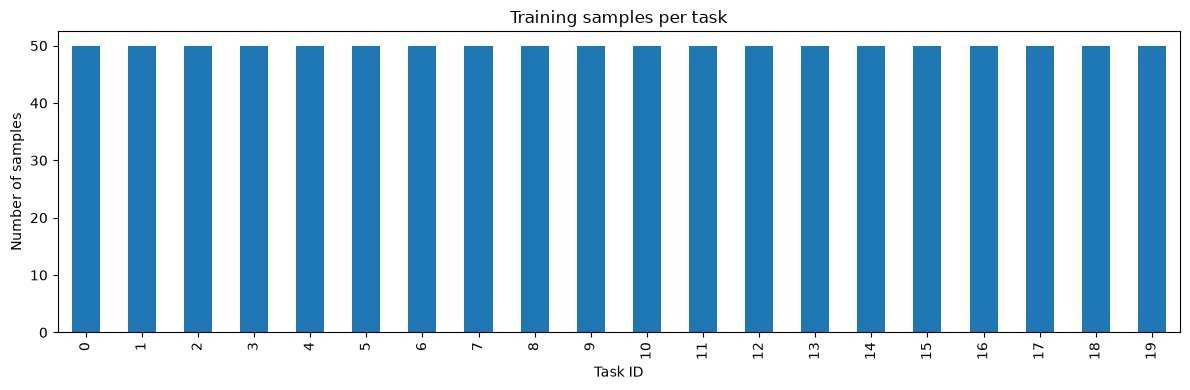

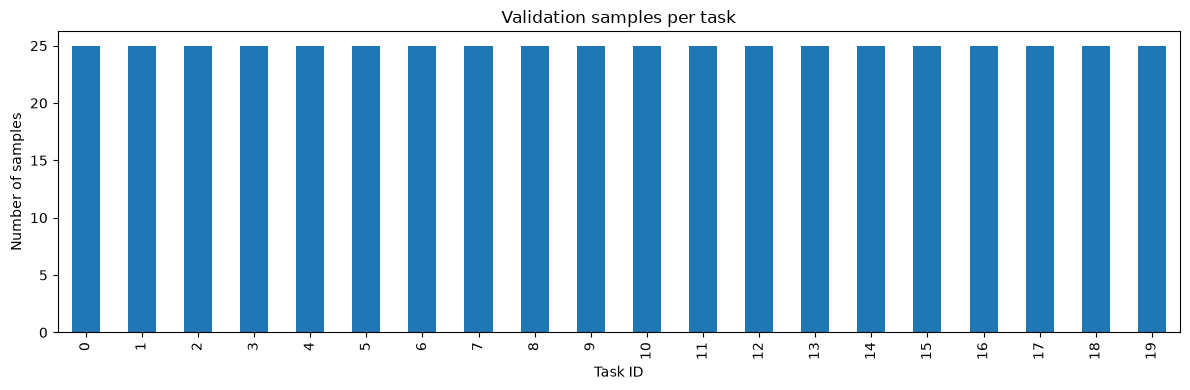

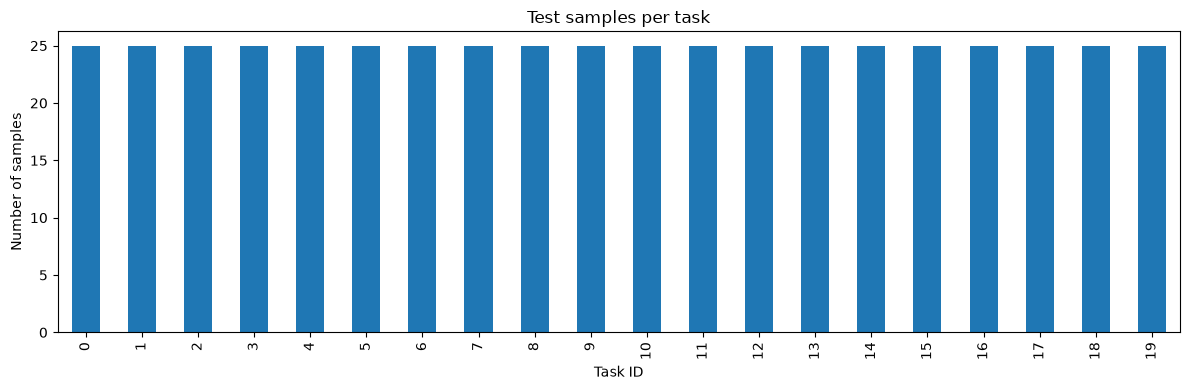

In [8]:
task_distribution = (
    df_train["task_id"]
    .value_counts()
    .sort_index()
)

ax = task_distribution.plot(
    kind="bar",
    figsize=(12, 4),
    title="Training samples per task",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "task_distribution_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a plottare la distribuzione del training set:
#tutti i task hanno lo stesso numero di esempi


task_distribution = (
    df_val["task_id"]
    .value_counts()
    .sort_index()
)

ax = task_distribution.plot(
    kind="bar",
    figsize=(12, 4),
    title="Validation samples per task",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "task_distribution_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


task_distribution = (
    df_test["task_id"]
    .value_counts()
    .sort_index()
)

ax = task_distribution.plot(
    kind="bar",
    figsize=(12, 4),
    title="Test samples per task",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "task_distribution_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

### Distribuzione delle etichette

In [9]:
label_distribution_train = df_train["label"].value_counts().sort_index()
print(label_distribution_train)

label_distribution_val = df_val["label"].value_counts().sort_index()
print(label_distribution_val)

label_distribution_test = df_test["label"].value_counts().sort_index()
print(label_distribution_test)

      
#andiamo a vedere come sono distribuite le label, cioè quanti esempi positivi e negativi abbiamo per ciascuna classe

label
0    594
1    406
Name: count, dtype: int64
label
0    271
1    229
Name: count, dtype: int64
label
0    294
1    206
Name: count, dtype: int64


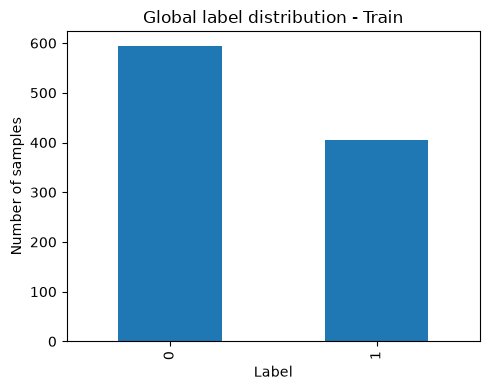

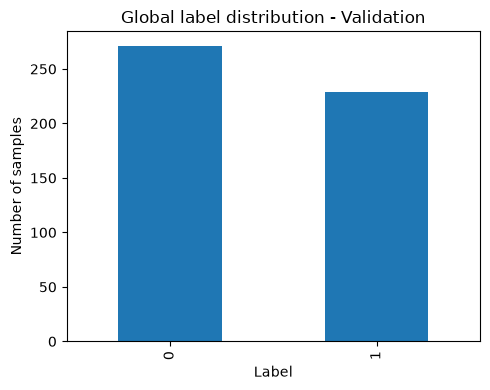

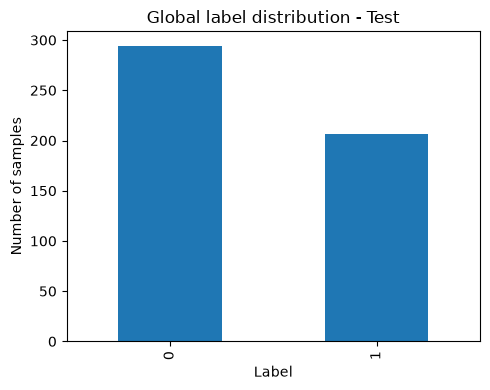

In [10]:
ax = label_distribution_train.plot(
    kind="bar",
    figsize=(5, 4),
    title="Global label distribution - Train",
)
ax.set_xlabel("Label")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "label_distribution_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a plottare la distribuzione della label e notiamo che ci sono
#più esempi negativi (ciò che non è)
#che esempi positivi (ciò che è)


ax = label_distribution_val.plot(
    kind="bar",
    figsize=(5, 4),
    title="Global label distribution - Validation",
)
ax.set_xlabel("Label")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "label_distribution_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


ax = label_distribution_test.plot(
    kind="bar",
    figsize=(5, 4),
    title="Global label distribution - Test",
)
ax.set_xlabel("Label")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "label_distribution_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

In [11]:
majority_baseline = df_train["label"].value_counts(normalize=True).max()
print(f"Majority baseline accuracy: {majority_baseline:.2%}")
#andiamo ora a contare gli esempi per classe in percentuale ed estraiamo la percentuale più ampia,
#in particolare, c'interesserà che il nostro modello superi questa percentuale di accuracy
#e non che classifiche semplicemente tutto il dataset come la classe maggioritaria

Majority baseline accuracy: 59.40%


### Distribuzione delle etichette per task

In [12]:
task_labels_train = (
    df_train.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
)
#raggruppo il dataset per task_id e vado a contare le label per ciascun task (50 per task come avevamo visto prima)
#e aggiungo due colonne 

task_labels_train["negatives"] = task_labels_train["total"] - task_labels_train["positives"]
task_labels_train["positive_ratio"] = task_labels_train["positives"] / task_labels_train["total"]
#vado a calcolare n_label_positive, n_label_negative e il rapporto tra esempi positivi ed esempi totali

print(task_labels_train)
#si noti che su quasi tutti i casi il numero di esempi positivi è strettamente minore di quelli negativi,
#nel task 19 (semaforo), abbiamo che solo il 10% degli esempi è positivo

task_labels_val = (
    df_val.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
) 

task_labels_val["negatives"] = task_labels_val["total"] - task_labels_val["positives"]
task_labels_val["positive_ratio"] = task_labels_val["positives"] / task_labels_val["total"]

print(task_labels_val)


task_labels_test = (
    df_test.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
)

task_labels_test["negatives"] = task_labels_test["total"] - task_labels_test["positives"]
task_labels_test["positive_ratio"] = task_labels_test["positives"] / task_labels_test["total"]

print(task_labels_test)

         total  positives  negatives  positive_ratio
task_id                                             
0           50         20         30            0.40
1           50         20         30            0.40
2           50         28         22            0.56
3           50         13         37            0.26
4           50         13         37            0.26
5           50         11         39            0.22
6           50         11         39            0.22
7           50         14         36            0.28
8           50         15         35            0.30
9           50         21         29            0.42
10          50         30         20            0.60
11          50         30         20            0.60
12          50         23         27            0.46
13          50         29         21            0.58
14          50         30         20            0.60
15          50         27         23            0.54
16          50         20         30          

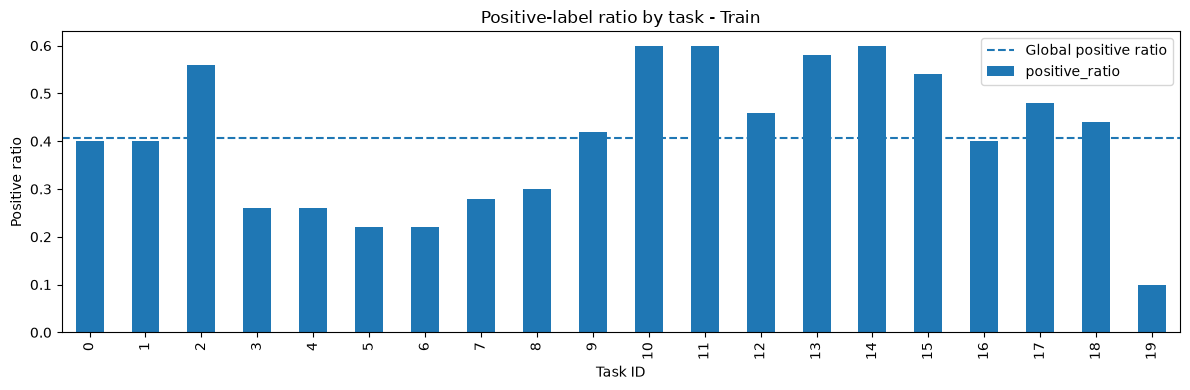

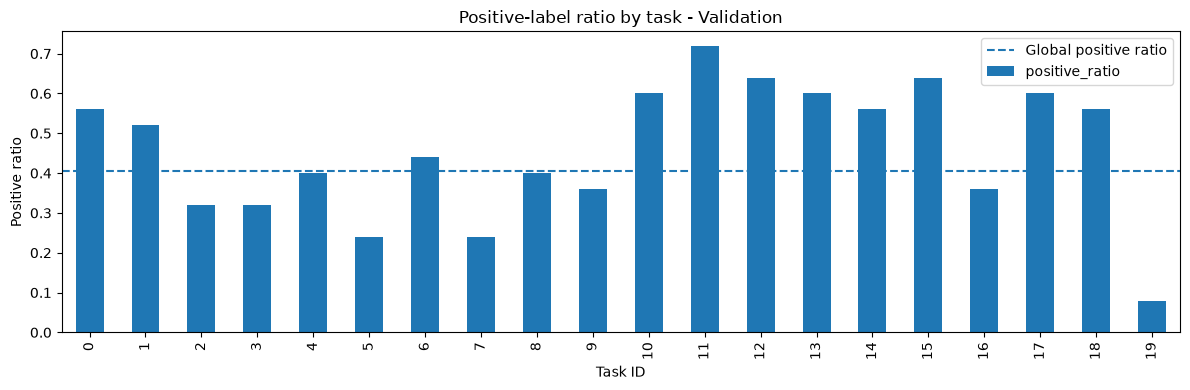

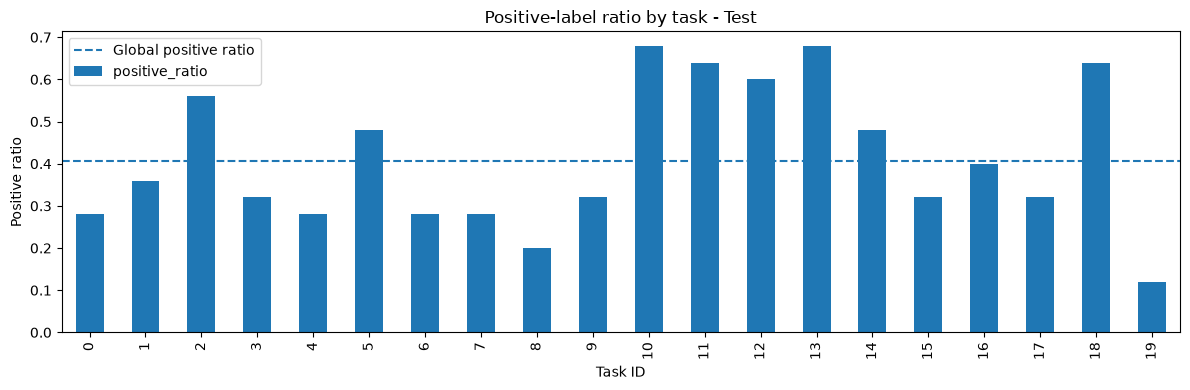

In [13]:
ax = task_labels_train["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Train",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a visualizzare il risultato.
#siccome la distribuzione degli esempi positivi tra i vari task varia,
#ed è spesso sbilanciata, dovremo utilizzare anche metriche diverse
#per valutare i modelli:
#precision, recall, F1


ax = task_labels_val["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Validation",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


ax = task_labels_test["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Test",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

### Parsing delle annotazioni simboliche

In [14]:
df_train["symbol_parsed"] = df_train["symbol"].apply(ast.literal_eval)
df_val["symbol_parsed"] = df_val["symbol"].apply(ast.literal_eval)
df_test["symbol_parsed"] = df_test["symbol"].apply(ast.literal_eval)
#nel dataset gli esempi sono costruiti a partire dal "symbol" ovvero:
#si hanno delle stringhe in un file yaml e tramite un generatore:
#
#qui andiamo a utilizzare ast per trasformare ciascuna stringa
#dizionario python, questo ci servirà per estrarre alcune
#statistiche importanti dai dati, in particolare:
#quante volte un certo concetto è stato utilizzato.

df_train[["filename", "task_id", "label", "symbol", "symbol_parsed"]].head()


,filename,task_id,label,symbol,symbol_parsed
0,0/0000.png,0,1,"{'quadrant_lr': [{'shape': 'triangle', 'color'...","{'quadrant_lr': [{'shape': 'triangle', 'color'..."
1,0/0001.png,0,0,"{'quadrant_lr': [{'shape': 'circle', 'color': ...","{'quadrant_lr': [{'shape': 'circle', 'color': ..."
2,0/0002.png,0,0,"{'quadrant_ur': [{'shape': 'circle', 'color': ...","{'quadrant_ur': [{'shape': 'circle', 'color': ..."
3,0/0003.png,0,1,"{'quadrant_ll': [{'shape': 'triangle', 'color'...","{'quadrant_ll': [{'shape': 'triangle', 'color'..."
4,0/0004.png,0,0,"{'quadrant_ul': [{'shape': 'circle', 'color': ...","{'quadrant_ul': [{'shape': 'circle', 'color': ..."


### Analisi dei concetti simbolici

In [15]:
def iter_objects(symbol):
    for position, objects in symbol.items():
        for obj in objects:
            yield position, obj

#funzione "comoda" che ci servira' dopo,
#prendiamo la lista delle descrizioni simboliche e,
#ogni volta che chiamiamo la funzione, questa
#ci restituisce "on the fly" la coppia position, object successiva

structure_counter = Counter()

for symbol in df_train["symbol_parsed"]:
    for position, objects in symbol.items():
        for obj in objects:
            structure_counter[tuple(sorted(obj.keys()))] += 1


for symbol in df_val["symbol_parsed"]:
    for position, objects in symbol.items():
        for obj in objects:
            structure_counter[tuple(sorted(obj.keys()))] += 1


for symbol in df_test["symbol_parsed"]:
    for position, objects in symbol.items():
        for obj in objects:
            structure_counter[tuple(sorted(obj.keys()))] += 1
#qui contiamo quante volte compare ogni struttura di attributi
#negli oggetti presenti nelle descrizioni simboliche.

print("Different object structures found:")
for structure, count in structure_counter.items():
    print(f"{count:4d} -> {structure}")


Different object structures found:
2733 -> ('color', 'shape', 'size')
  12 -> ('grid',)
 315 -> ('stack',)
  14 -> ('stack_reduce_bb',)
  20 -> ('diag_ul_lr',)
  15 -> ('diag_ll_ur',)
  12 -> ('side_by_side_reduce_bb',)
 212 -> ('side_by_side',)


=======TRAINSET=======
Shape counts: {'triangle': 523, 'circle': 428, 'square': 417}
Color counts: {'blue': 236, 'cyan': 195, 'magenta': 193, 'yellow': 209, 'green': 207, 'red': 328}
Size counts: {'large': 676, 'small': 692}
Position counts: {'quadrant_lr': 130, 'quadrant_ur': 157, 'quadrant_ll': 150, 'quadrant_ul': 164, 'in': 149, 'side_by_side': 918}


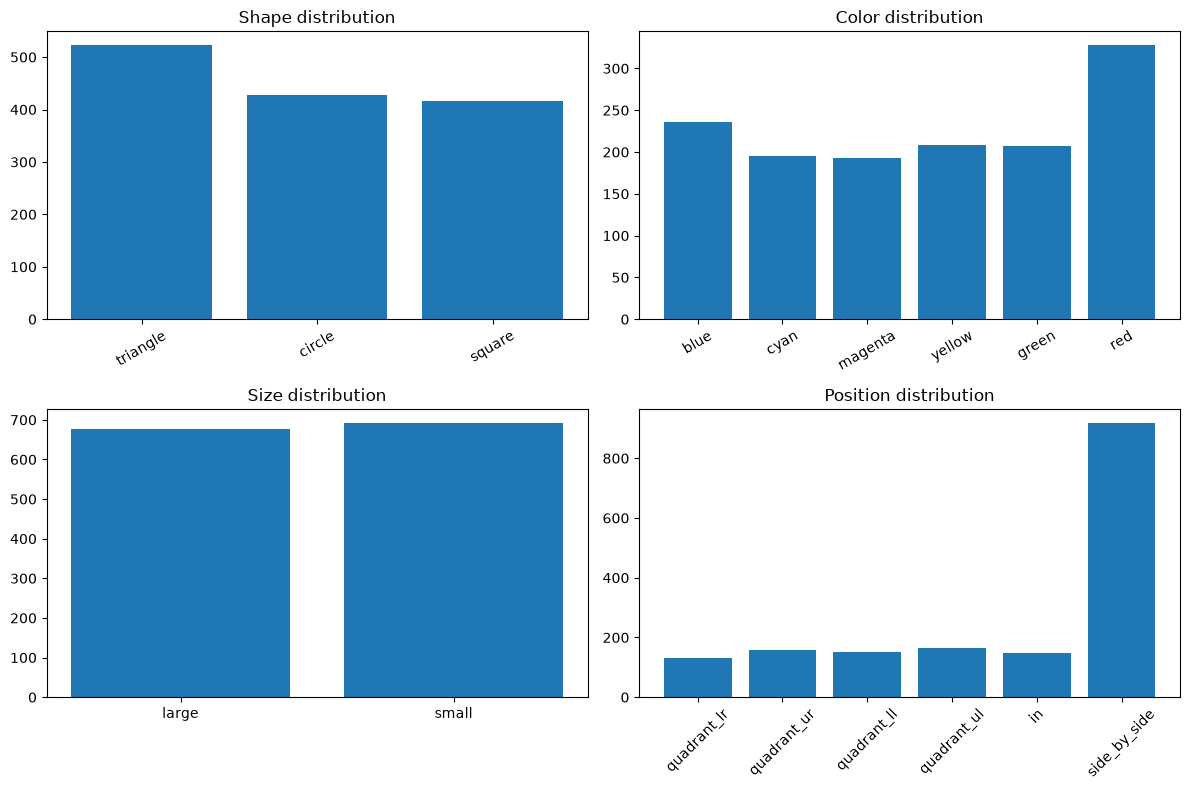

=======VALIDATIONSET=======
Shape counts: {'square': 204, 'triangle': 284, 'circle': 198}
Color counts: {'yellow': 107, 'green': 92, 'blue': 119, 'magenta': 96, 'red': 174, 'cyan': 98}
Size counts: {'small': 324, 'large': 362}
Position counts: {'quadrant_ul': 74, 'quadrant_ur': 69, 'quadrant_lr': 81, 'quadrant_ll': 83, 'in': 68, 'side_by_side': 461}


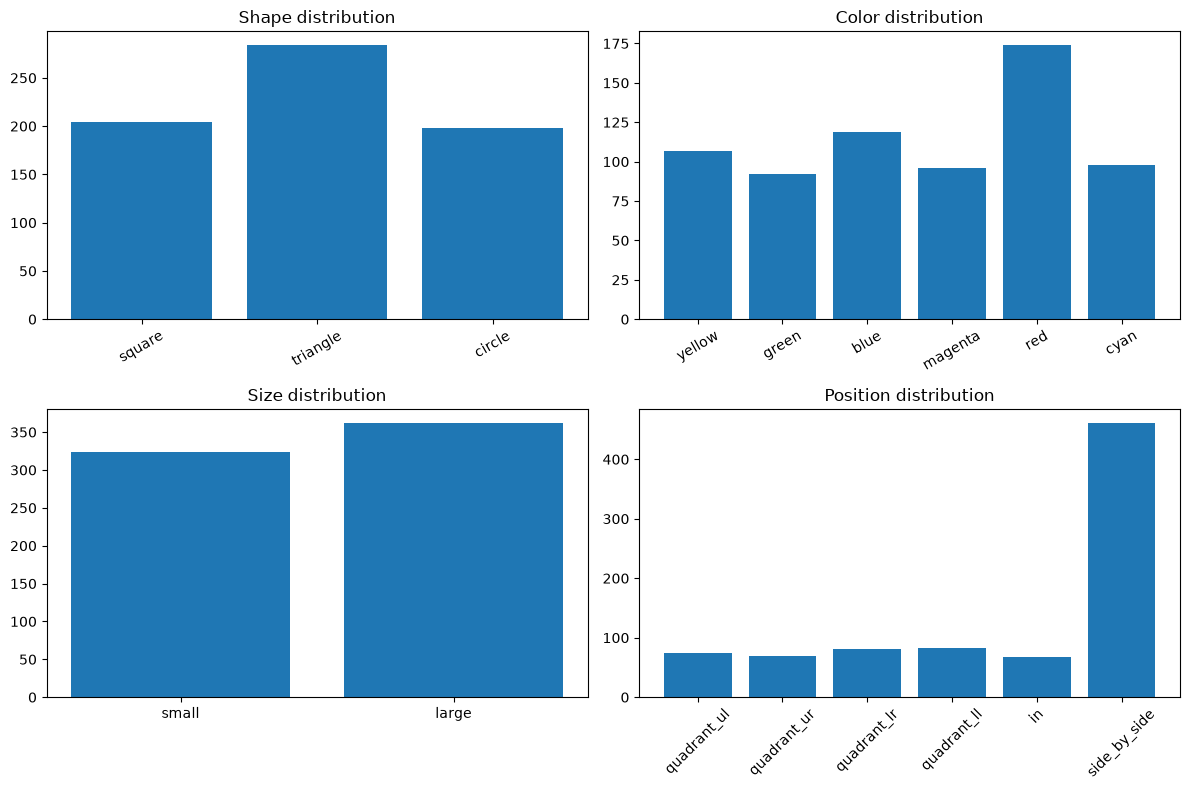

=======TESTSET=======
Shape counts: {'triangle': 259, 'circle': 235, 'square': 185}
Color counts: {'blue': 116, 'red': 177, 'cyan': 99, 'magenta': 97, 'yellow': 84, 'green': 106}
Size counts: {'large': 345, 'small': 334}
Position counts: {'quadrant_ul': 75, 'in': 72, 'quadrant_ur': 69, 'quadrant_lr': 80, 'quadrant_ll': 79, 'side_by_side': 454}


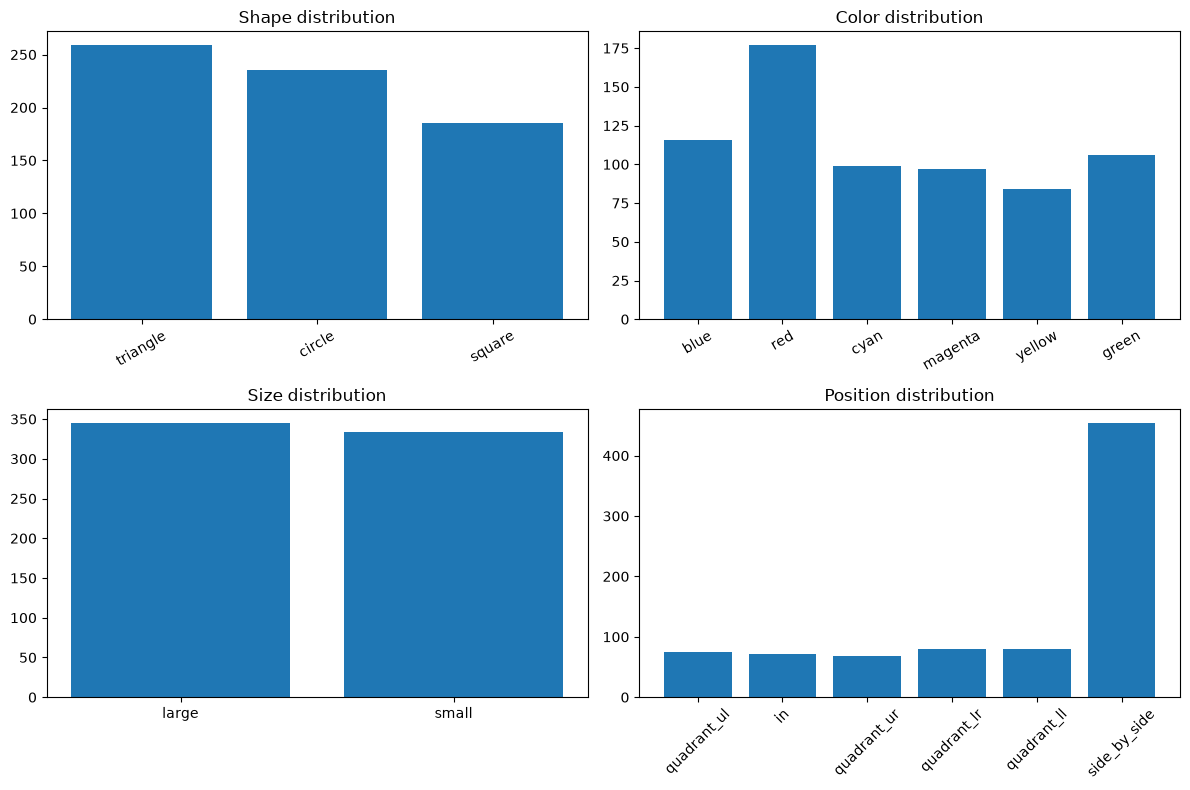

In [16]:
shape_counter = Counter()
color_counter = Counter()
size_counter = Counter()
position_counter = Counter()

for symbol in df_train["symbol_parsed"]:
    for position, obj in iter_objects(symbol):
        position_counter[position] += 1

        if "shape" in obj:
            shape_counter[obj["shape"]] += 1

        if "color" in obj:
            color_counter[obj["color"]] += 1

        if "size" in obj:
            size_counter[obj["size"]] += 1

#qui andiamo a estrarre tutte le descrizioni simboliche,
#dopodiché, utilizzando la funzione di prima, andiamo a
#estrarre uno a uno gli oggetti con la loro posizione

print("=======TRAINSET=======")
print("Shape counts:", dict(shape_counter))
print("Color counts:", dict(color_counter))
print("Size counts:", dict(size_counter))
print("Position counts:", dict(position_counter))

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

axes[0, 0].bar(
    shape_counter.keys(),
    shape_counter.values(),
)
axes[0, 0].set_title("Shape distribution")
axes[0, 0].tick_params(
    axis="x",
    rotation=30,
)

axes[0, 1].bar(
    color_counter.keys(),
    color_counter.values(),
)
axes[0, 1].set_title("Color distribution")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)

axes[1, 0].bar(
    size_counter.keys(),
    size_counter.values(),
)
axes[1, 0].set_title("Size distribution")

axes[1, 1].bar(
    position_counter.keys(),
    position_counter.values(),
)
axes[1, 1].set_title("Position distribution")
axes[1, 1].tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_properties_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close(fig)

shape_counter = Counter()
color_counter = Counter()
size_counter = Counter()
position_counter = Counter()
#reset dei contatori prima di analizzare il validation set

for symbol in df_val["symbol_parsed"]:
    for position, obj in iter_objects(symbol):
        position_counter[position] += 1

        if "shape" in obj:
            shape_counter[obj["shape"]] += 1

        if "color" in obj:
            color_counter[obj["color"]] += 1

        if "size" in obj:
            size_counter[obj["size"]] += 1

print("=======VALIDATIONSET=======")
print("Shape counts:", dict(shape_counter))
print("Color counts:", dict(color_counter))
print("Size counts:", dict(size_counter))
print("Position counts:", dict(position_counter))

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

axes[0, 0].bar(
    shape_counter.keys(),
    shape_counter.values(),
)
axes[0, 0].set_title("Shape distribution")
axes[0, 0].tick_params(
    axis="x",
    rotation=30,
)

axes[0, 1].bar(
    color_counter.keys(),
    color_counter.values(),
)
axes[0, 1].set_title("Color distribution")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)

axes[1, 0].bar(
    size_counter.keys(),
    size_counter.values(),
)
axes[1, 0].set_title("Size distribution")

axes[1, 1].bar(
    position_counter.keys(),
    position_counter.values(),
)
axes[1, 1].set_title("Position distribution")
axes[1, 1].tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_properties_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close(fig)

shape_counter = Counter()
color_counter = Counter()
size_counter = Counter()
position_counter = Counter()
#reset dei contatori prima di analizzare il test set

for symbol in df_test["symbol_parsed"]:
    for position, obj in iter_objects(symbol):
        position_counter[position] += 1

        if "shape" in obj:
            shape_counter[obj["shape"]] += 1

        if "color" in obj:
            color_counter[obj["color"]] += 1

        if "size" in obj:
            size_counter[obj["size"]] += 1

print("=======TESTSET=======")
print("Shape counts:", dict(shape_counter))
print("Color counts:", dict(color_counter))
print("Size counts:", dict(size_counter))
print("Position counts:", dict(position_counter))

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

axes[0, 0].bar(
    shape_counter.keys(),
    shape_counter.values(),
)
axes[0, 0].set_title("Shape distribution")
axes[0, 0].tick_params(
    axis="x",
    rotation=30,
)

axes[0, 1].bar(
    color_counter.keys(),
    color_counter.values(),
)
axes[0, 1].set_title("Color distribution")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)

axes[1, 0].bar(
    size_counter.keys(),
    size_counter.values(),
)
axes[1, 0].set_title("Size distribution")

axes[1, 1].bar(
    position_counter.keys(),
    position_counter.values(),
)
axes[1, 1].set_title("Position distribution")
axes[1, 1].tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_properties_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close(fig)

### Numero di oggetti per immagine

In [17]:
def count_objects(symbol):
    return sum(len(objects) for objects in symbol.values())
#questa funzione ci permette di ottenere il numero totale di oggetti per descrizione simbolica

print("=======TRAINING=======")
df_train["num_objects"] = df_train["symbol_parsed"].apply(count_objects)
#andiamo a contare per ciascuna entrata
print(df_train["num_objects"].describe())
#otteniamo alcune statistiche: la maggior parte dei task ha 1 oggetto,
#il task col maggior numero ne ha 6

print("=======VAL=======")
df_val["num_objects"] = df_val["symbol_parsed"].apply(count_objects)
print(df_val["num_objects"].describe())

print("=======TEST=======")
df_test["num_objects"] = df_test["symbol_parsed"].apply(count_objects)
print(df_test["num_objects"].describe())

=======TRAINING=======
count    1000.000000
mean        1.668000
std         1.339989
min         1.000000
25%         1.000000
50%         1.000000
75%         1.250000
max         6.000000
Name: num_objects, dtype: float64
=======VAL=======
count    500.000000
mean       1.672000
std        1.352062
min        1.000000
25%        1.000000
50%        1.000000
75%        1.250000
max        6.000000
Name: num_objects, dtype: float64
=======TEST=======
count    500.000000
mean       1.658000
std        1.313196
min        1.000000
25%        1.000000
50%        1.000000
75%        1.250000
max        6.000000
Name: num_objects, dtype: float64


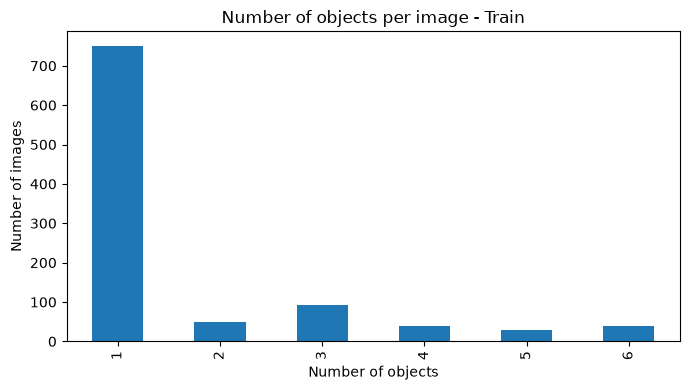

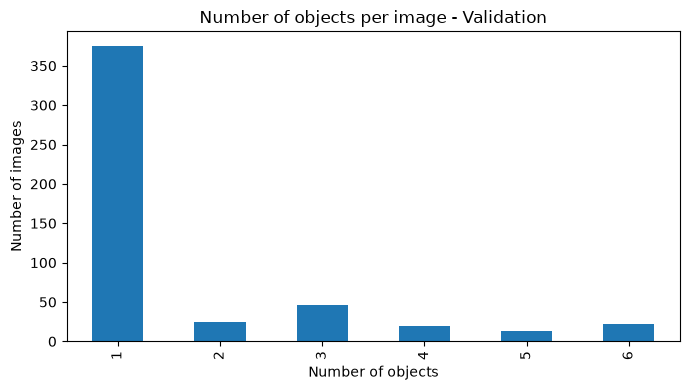

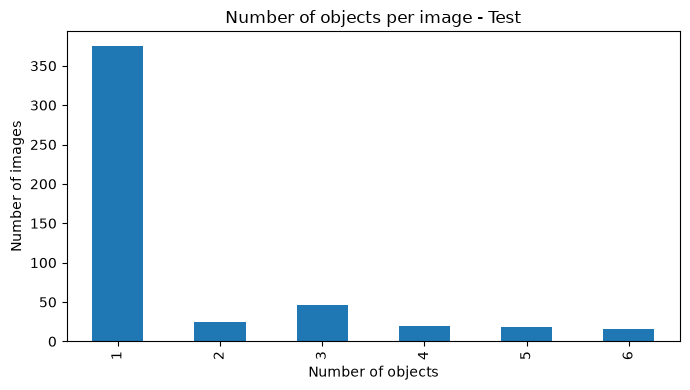

In [18]:
object_counts = (
    df_train["num_objects"]
    .value_counts()
    .sort_index()
)

ax = object_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of objects per image - Train",
)

ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_count_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()


object_counts = (
    df_val["num_objects"]
    .value_counts()
    .sort_index()
)

ax = object_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of objects per image - Validation",
)

ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_count_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


object_counts = (
    df_test["num_objects"]
    .value_counts()
    .sort_index()
)

ax = object_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of objects per image - Test",
)

ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_count_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

#la maggior parte degli esempi ha un solo oggetto.

### Estrazione dei concetti interpretabili

In [19]:
def extract_concepts(symbol):
    objects = list(iter_objects(symbol))

    if not objects:
        return {
            "position": None,
            "shape": None,
            "color": None,
            "size": None,
            "num_objects": 0,
        }

    position, obj = objects[0]

    return {
        "position": position,
        "shape": obj.get("shape"),
        "color": obj.get("color"),
        "size": obj.get("size"),
        "num_objects": len(objects),
    }
#questa funzione serve per, data una descrizione simbolica ottenerne
#i concetti interpretabili, estrarne alcune proprietà
#interpretabili dell'oggetto e il numero totale di oggetti presenti.

concepts = df_train["symbol_parsed"].apply(extract_concepts)
#otteniamo dizionario concetti
concept_df = pd.DataFrame(concepts.tolist())
#li uniamo in una lista di dizionari, e facciamo diventare le chiavi dizionari
#delle colonne di un dataframe

df_concepts = pd.concat(
    [
        df_train[["filename", "task_id", "label"]].reset_index(drop=True),
        concept_df.reset_index(drop=True),
    ],
    axis=1,
)
#a questo affianchiamo le colonne ottenute dal dataframe, accanto a quelle originali.


df_concepts.head(200)


,filename,task_id,label,position,shape,color,size,num_objects
0,0/0000.png,0,1,quadrant_lr,triangle,blue,large,1
1,0/0001.png,0,0,quadrant_lr,circle,cyan,small,1
2,0/0002.png,0,0,quadrant_ur,circle,blue,small,1
3,0/0003.png,0,1,quadrant_ll,triangle,magenta,small,1
4,0/0004.png,0,0,quadrant_ul,circle,blue,large,1
...,...,...,...,...,...,...,...,...
195,3/0045.png,3,1,quadrant_lr,square,red,large,1
196,3/0046.png,3,0,quadrant_ul,circle,blue,large,1
197,3/0047.png,3,0,quadrant_ul,square,yellow,small,1
198,3/0048.png,3,0,quadrant_lr,square,magenta,small,1


### Visualizzazione delle immagini

Image path: /home/cosimo/progetti/tesi/data/easy/samples/sets/train/0/0000.png
Image size: (224, 224)
Task: 0
Label: 1
Symbol: {'quadrant_lr': [{'shape': 'triangle', 'color': 'blue', 'size': 'large'}]}


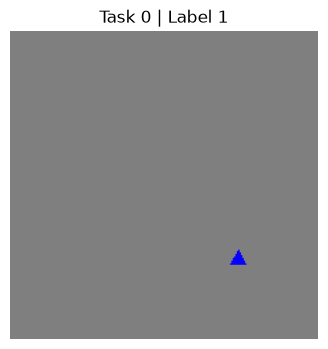

In [20]:
sample = df_train.iloc[0]
#accedo al dataframe di train e prendo la prima riga (prima immagine)

img_path = TRAIN_DIR / sample["filename"]
img = Image.open(img_path)

print("Image path:", img_path)
print("Image size:", img.size)
print("Task:", sample["task_id"])
print("Label:", sample["label"])
print("Symbol:", sample["symbol"])

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis("off")
plt.title(f"Task {sample.task_id} | Label {sample.label}")
plt.show()
#plottiamo task, label, concetti interpretabili contenuti nell'immagine e l'immagine

### Esempi positivi e negativi con descrizione

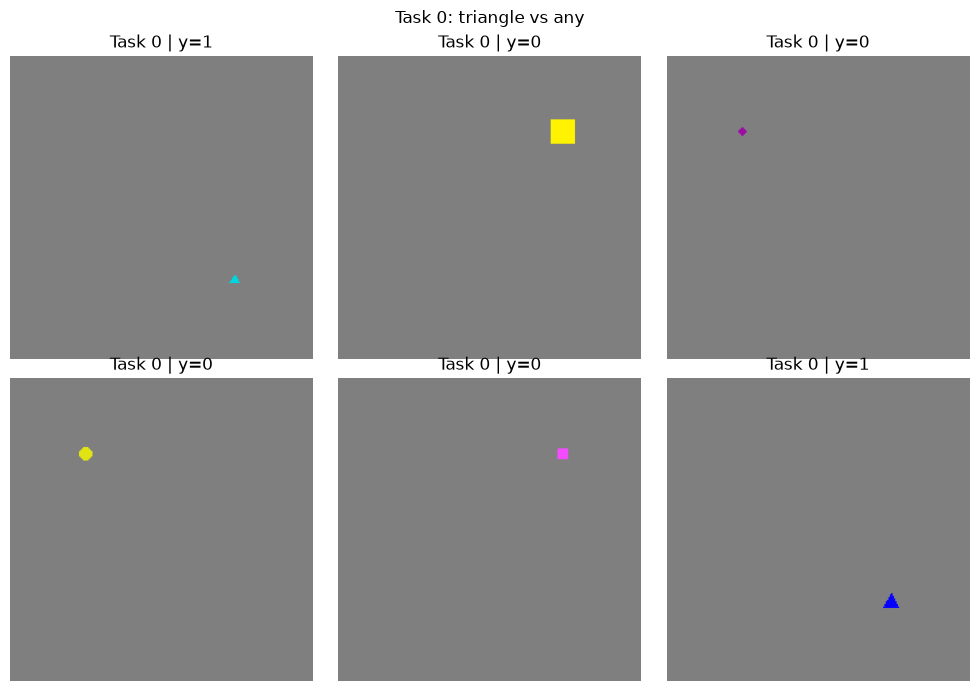

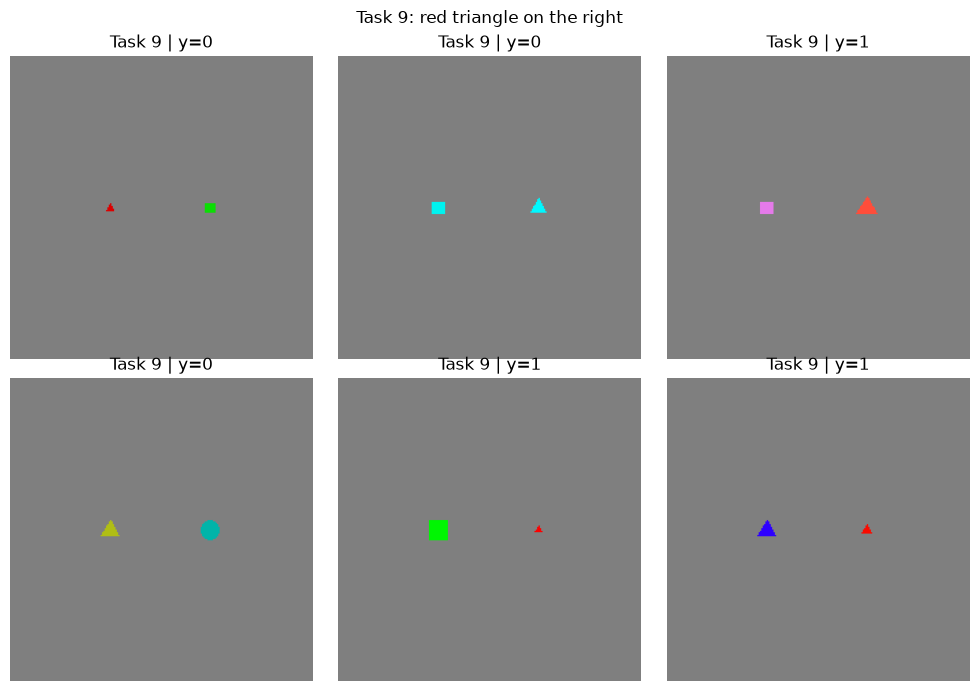

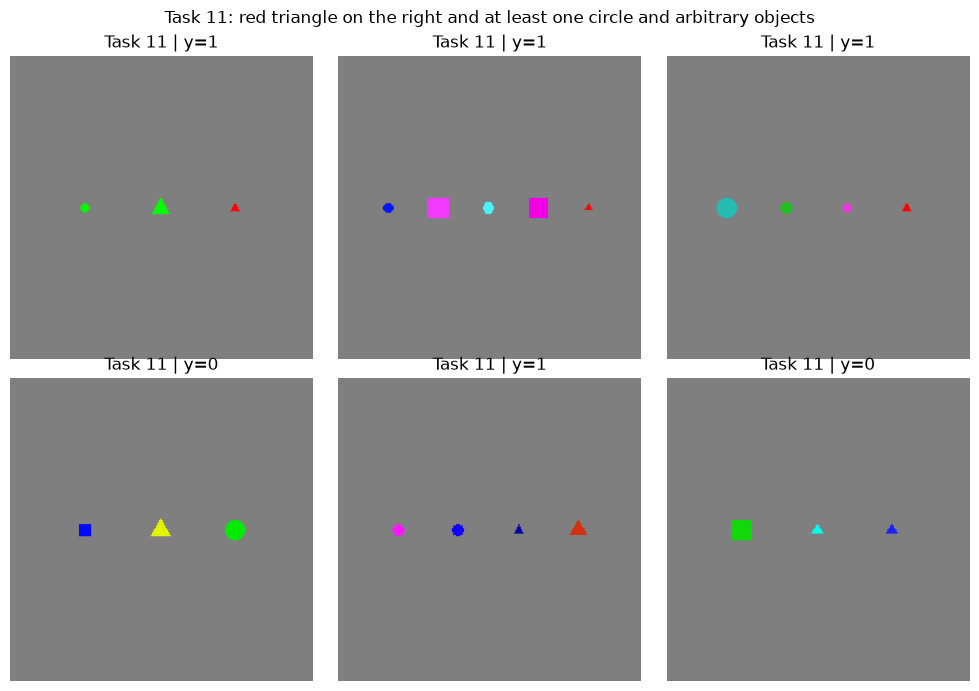

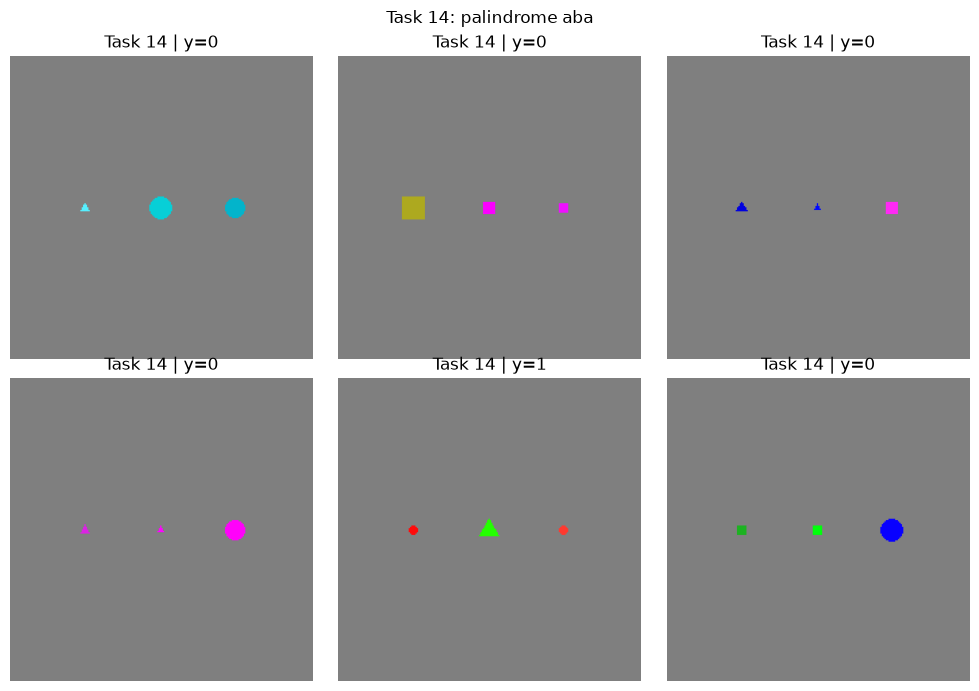

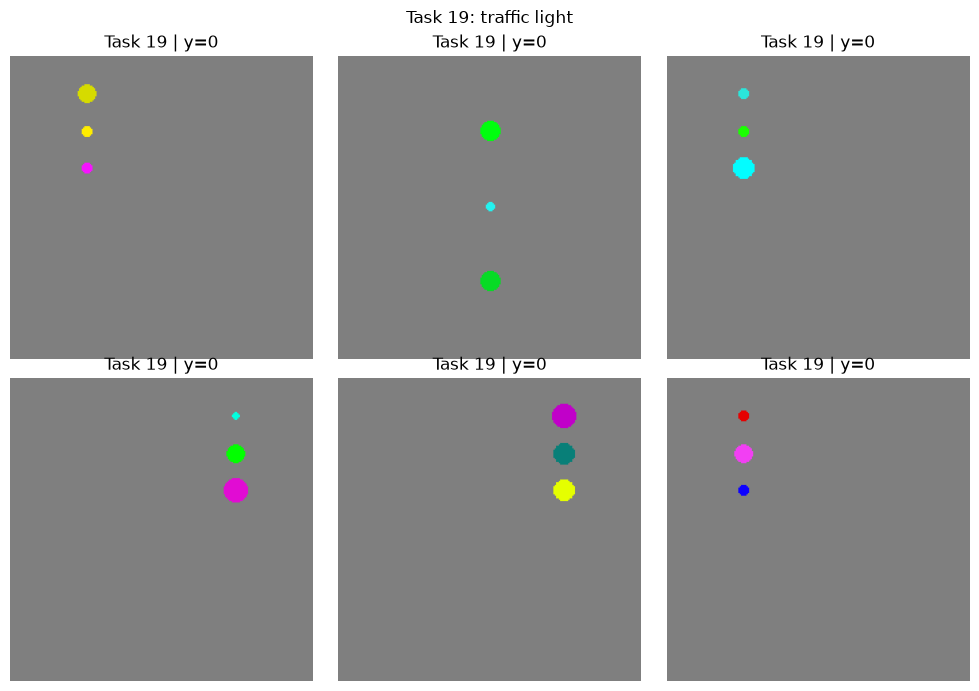

In [21]:
task_names = {
    0: "triangle vs any",
    1: "square vs any",
    2: "circle vs any",
    3: "red vs any",
    4: "green vs any",
    5: "blue vs any",
    6: "cyan vs any",
    7: "magenta vs any",
    8: "yellow vs any",
    9: "red triangle on the right",
    10: "red triangle on the right and arbitrary objects",
    11: "red triangle on the right and at least one circle and arbitrary objects",
    12: "red triangle on the right and at least one blue object and arbitrary objects",
    13: "triangle and square, same color",
    14: "palindrome aba",
    15: "house",
    16: "car",
    17: "tower",
    18: "wagon",
    19: "traffic light",
}

def show_task_examples(df, task_id, n=6, seed=123):
    subset = df[df["task_id"] == task_id]
    samples = subset.sample(n=min(n, len(subset)), random_state=seed)

    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, samples.iterrows()):
        img = Image.open(TRAIN_DIR / row["filename"])
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"Task {row.task_id} | y={row.label}")

    fig.suptitle(f"Task {task_id}: {task_names[task_id]}")
    plt.tight_layout()

    fig.savefig(
        PLOTS_DIR / f"task_{task_id}_examples.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
    #salva l'immagine e chiude la figura

for task_id in [0, 9, 11, 14, 19]:
    show_task_examples(df_train, task_id)
#plottiamo e salviamo alcuni esempi per i task selezionati

### Panoramica delle task

In [22]:
task_overview = task_labels_train.copy()
task_overview["task_name"] = task_overview.index.map(task_names)

task_overview[
    ["task_name", "total", "positives", "negatives", "positive_ratio"]
]

#piccolo riassunto finale.

,task_name,total,positives,negatives,positive_ratio
task_id,,,,,
0,triangle vs any,50,20,30,0.40
1,square vs any,50,20,30,0.40
2,circle vs any,50,28,22,0.56
3,red vs any,50,13,37,0.26
4,green vs any,50,13,37,0.26
5,blue vs any,50,11,39,0.22
6,cyan vs any,50,11,39,0.22
7,magenta vs any,50,14,36,0.28
8,yellow vs any,50,15,35,0.30


### Conclusioni KANDY-EASY

Il dataset contiene dunque:

- 1000 immagini di training;
- 20 task di classificazione binaria;
- 50 campioni di training per task;
- annotazioni simboliche che descrivono le scene;
- concetti interpretabili come forma, colore, dimensione e posizione;
- regole logiche differenti tra le task.

La baseline globale ottenuta considerando il modello che predice la classe maggioritaria è circa 59,4%

## KANDY-HARD

In [23]:
from pathlib import Path
#mi permette di gestire più agilmente i percorsi
from collections import Counter
#mi permette di contare quante volte un elemento compare in una sequenza
import ast
#permette di trasformate una stringa di dati in una struttura dati di python
#es.: "[1,2,3]" -> [1, 2, 3]
import pandas as pd
import pandas as pd
import pandas as pd
#pandas per gestione dati tabellari
import matplotlib.pyplot as plt
#matplotlib per grafici
from PIL import Image
#pillow per lavorare con le immagini


PROJECT_ROOT = Path.cwd().parent
#ottengo la cartella di lavoro corrente

DATA_DIR = PROJECT_ROOT / "data" / "hard" / "samples" / "sets"

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

TRAIN_CSV = TRAIN_DIR / "annotations.csv"
VAL_CSV = VAL_DIR / "annotations.csv"
TEST_CSV = TEST_DIR / "annotations.csv"
#creo i vari percorsi/file in cui salvare i risultati

RESULTS_DIR = PROJECT_ROOT / "results"
PLOTS_DIR = RESULTS_DIR / "dataset_exploration"
PLOTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
#crea la cartella in cui salviamo tutti i risultati del notebook

print("Project root:", PROJECT_ROOT)
print("Train directory:", TRAIN_DIR)
print("Validation directory:", VAL_DIR)
print("Test directory:", TEST_DIR)


Project root: /home/cosimo/progetti/tesi
Train directory: /home/cosimo/progetti/tesi/data/hard/samples/sets/train
Validation directory: /home/cosimo/progetti/tesi/data/hard/samples/sets/val
Test directory: /home/cosimo/progetti/tesi/data/hard/samples/sets/test


### Caricamento delle annotazioni

In [24]:
df_train = pd.read_csv(TRAIN_CSV)
df_val = pd.read_csv(VAL_CSV)
df_test = pd.read_csv(TEST_CSV)
#estraiamo i contenuti dai csv del dataset

print("Train samples:", len(df_train))
print("Validation samples:", len(df_val))
print("Test samples:", len(df_test))
#verifichiamo la grandezza del dataset

df_train.head()
#mostriamo i primi esempi del dataset di training

Train samples: 1290
Validation samples: 255
Test samples: 255


,filename,task_id,label,supervised,symbol
0,0/0000.png,0,0,1,{'quadrant_ul': [{'diag_ll_ur': [{'shape': 'ci...
1,0/0001.png,0,1,1,{'quadrant_ur': [{'side_by_side': [{'shape': '...
2,0/0002.png,0,0,1,{'quadrant_ur': [{'diag_ul_lr': [{'shape': 'ci...
3,0/0003.png,0,1,1,"{'in': [{'side_by_side': [{'shape': 'circle', ..."
4,0/0004.png,0,1,1,"{'in': [{'side_by_side': [{'shape': 'square', ..."


In [25]:
df_train.info()
#andiamo a osservare alcune caratteristiche riassuntive sul dataset di training

<class 'pandas.DataFrame'>
RangeIndex: 1290 entries, 0 to 1289
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   filename    1290 non-null   str  
 1   task_id     1290 non-null   int64
 2   label       1290 non-null   int64
 3   supervised  1290 non-null   int64
 4   symbol      1290 non-null   str  
dtypes: int64(3), str(2)
memory usage: 50.5 KB


### Campi delle annotazioni

- `filename`: percorso relativo dell’immagine;
- `task_id`: identificatore della task KANDY;
- `label`: etichetta binaria;
- `supervised`: indicatore di supervisione;
- `symbol`: descrizione simbolica della scena.

### Statistiche del dataset

In [26]:
n_tasks = df_train["task_id"].nunique()
print("Number of tasks:", n_tasks)
#andiamo a contare quanti task differenti abbiamo

print("Training samples:", len(df_train))

print("\nSamples per task:")
print(df_train["task_id"].value_counts().sort_index())
#contiamo quanti esempi per task abbiamo e li ordiniamo per numero di valori

n_tasks = df_val["task_id"].nunique()
print("Number of tasks:", n_tasks)
#andiamo a contare quanti task differenti abbiamo

print("Validation samples:", len(df_val))

print("\nSamples per task:")
print(df_val["task_id"].value_counts().sort_index())
#contiamo quanti esempi per task abbiamo e li ordiniamo per numero di valori

n_tasks = df_test["task_id"].nunique()
print("Number of tasks:", n_tasks)
#andiamo a contare quanti task differenti abbiamo

print("Test samples:", len(df_test))

print("\nSamples per task:")
print(df_test["task_id"].value_counts().sort_index())
#contiamo quanti esempi per task abbiamo e li ordiniamo per numero di valori

Number of tasks: 18
Training samples: 1290

Samples per task:
task_id
0     80
1     80
2     80
3     80
4     50
5     50
6     50
7     50
8     50
9     80
10    80
11    80
12    80
13    80
14    80
15    80
16    80
17    80
Name: count, dtype: int64
Number of tasks: 18
Validation samples: 255

Samples per task:
task_id
0     10
1     10
2     10
3     10
4     25
5     25
6     25
7     25
8     25
9     10
10    10
11    10
12    10
13    10
14    10
15    10
16    10
17    10
Name: count, dtype: int64
Number of tasks: 18
Test samples: 255

Samples per task:
task_id
0     10
1     10
2     10
3     10
4     25
5     25
6     25
7     25
8     25
9     10
10    10
11    10
12    10
13    10
14    10
15    10
16    10
17    10
Name: count, dtype: int64


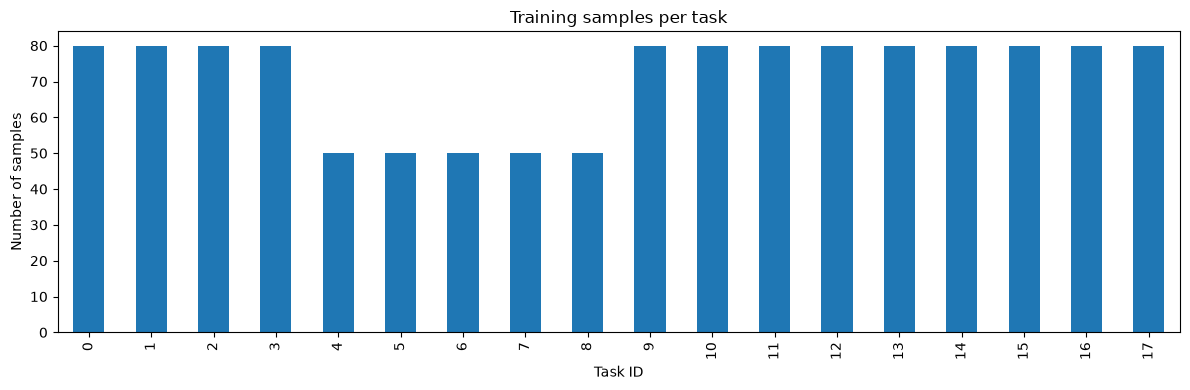

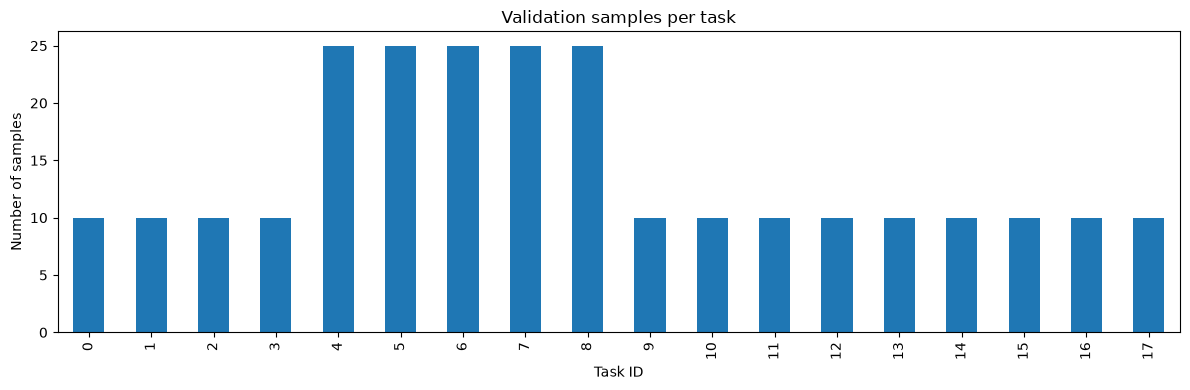

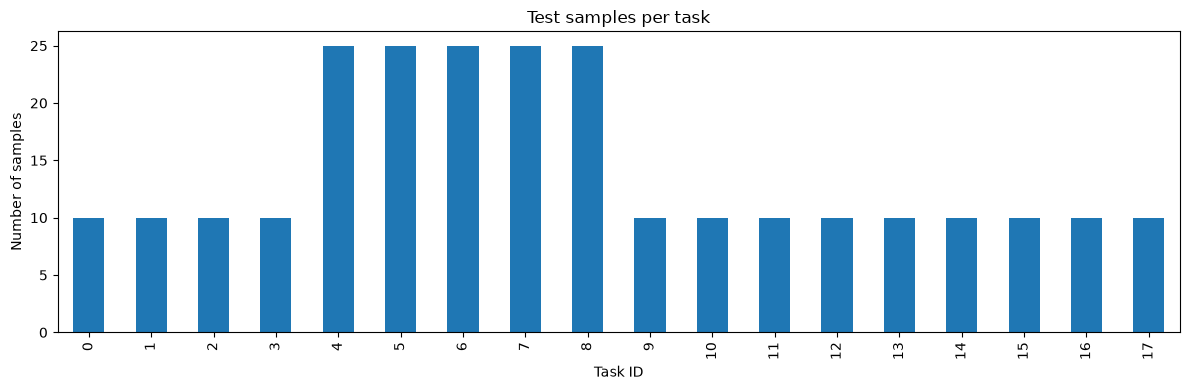

In [27]:
task_distribution = (
    df_train["task_id"]
    .value_counts()
    .sort_index()
)

ax = task_distribution.plot(
    kind="bar",
    figsize=(12, 4),
    title="Training samples per task",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "task_distribution_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a plottare la distribuzione del training set:
#tutti i task hanno lo stesso numero di esempi


task_distribution = (
    df_val["task_id"]
    .value_counts()
    .sort_index()
)

ax = task_distribution.plot(
    kind="bar",
    figsize=(12, 4),
    title="Validation samples per task",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "task_distribution_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


task_distribution = (
    df_test["task_id"]
    .value_counts()
    .sort_index()
)

ax = task_distribution.plot(
    kind="bar",
    figsize=(12, 4),
    title="Test samples per task",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "task_distribution_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

Si nota che per le classi 4-5-6-7-8 si ha che, relativamente al resto del dataset, abbiamo più esempi di validation e testing che di training.

### Distribuzione delle etichette

In [28]:
label_distribution_train = df_train["label"].value_counts().sort_index()
print(label_distribution_train)

label_distribution_val = df_val["label"].value_counts().sort_index()
print(label_distribution_val)

label_distribution_test = df_test["label"].value_counts().sort_index()
print(label_distribution_test)

      
#andiamo a vedere come sono distribuite le label, cioè quanti esempi positivi e negativi abbiamo per ciascuna classe

label
0    609
1    681
Name: count, dtype: int64
label
0    118
1    137
Name: count, dtype: int64
label
0    123
1    132
Name: count, dtype: int64


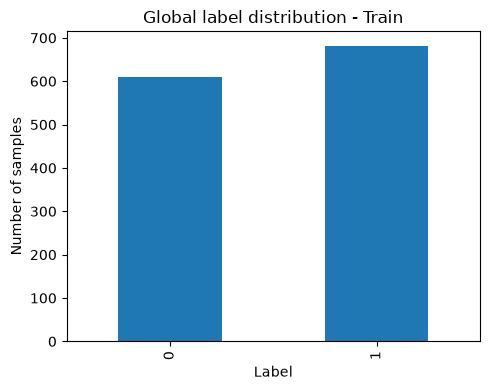

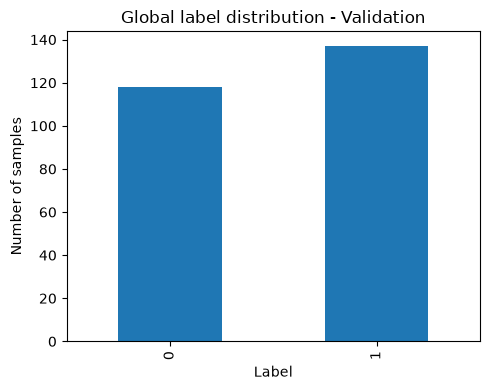

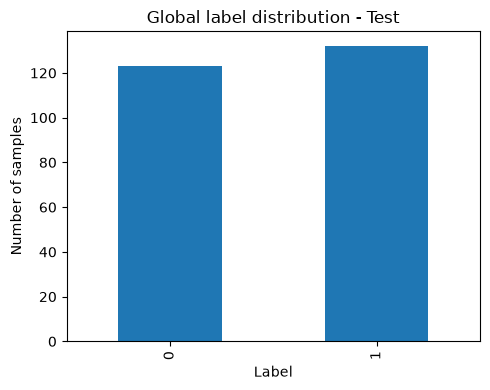

In [29]:
ax = label_distribution_train.plot(
    kind="bar",
    figsize=(5, 4),
    title="Global label distribution - Train",
)
ax.set_xlabel("Label")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "label_distribution_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a plottare la distribuzione della label e notiamo che ci sono
#più esempi negativi (ciò che non è)
#che esempi positivi (ciò che è)


ax = label_distribution_val.plot(
    kind="bar",
    figsize=(5, 4),
    title="Global label distribution - Validation",
)
ax.set_xlabel("Label")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "label_distribution_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


ax = label_distribution_test.plot(
    kind="bar",
    figsize=(5, 4),
    title="Global label distribution - Test",
)
ax.set_xlabel("Label")
ax.set_ylabel("Number of samples")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "label_distribution_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

Si nota che le label positive sono sensibilmente maggiori delle negative

In [30]:
majority_baseline = df_train["label"].value_counts(normalize=True).max()
print(f"Majority baseline accuracy: {majority_baseline:.2%}")
#andiamo ora a contare gli esempi per classe in percentuale ed estraiamo la percentuale più ampia,
#in particolare, c'interesserà che il nostro modello superi questa percentuale di accuracy
#e non che classifiche semplicemente tutto il dataset come la classe maggioritaria

Majority baseline accuracy: 52.79%


### Distribuzione delle etichette per task

In [31]:
task_labels_train = (
    df_train.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
)
#raggruppo il dataset per task_id e vado a contare le label per ciascun task (50 per task come avevamo visto prima)
#e aggiungo due colonne 

task_labels_train["negatives"] = task_labels_train["total"] - task_labels_train["positives"]
task_labels_train["positive_ratio"] = task_labels_train["positives"] / task_labels_train["total"]
#vado a calcolare n_label_positive, n_label_negative e il rapporto tra esempi positivi ed esempi totali

print(task_labels_train)
#si noti che su quasi tutti i casi il numero di esempi positivi è strettamente minore di quelli negativi,
#nel task 19 (semaforo), abbiamo che solo il 10% degli esempi è positivo

task_labels_val = (
    df_val.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
) 

task_labels_val["negatives"] = task_labels_val["total"] - task_labels_val["positives"]
task_labels_val["positive_ratio"] = task_labels_val["positives"] / task_labels_val["total"]

print(task_labels_val)


task_labels_test = (
    df_test.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
)

task_labels_test["negatives"] = task_labels_test["total"] - task_labels_test["positives"]
task_labels_test["positive_ratio"] = task_labels_test["positives"] / task_labels_test["total"]

print(task_labels_test)

         total  positives  negatives  positive_ratio
task_id                                             
0           80         36         44          0.4500
1           80         43         37          0.5375
2           80         38         42          0.4750
3           80         44         36          0.5500
4           50         30         20          0.6000
5           50         23         27          0.4600
6           50         25         25          0.5000
7           50         24         26          0.4800
8           50         29         21          0.5800
9           80         64         16          0.8000
10          80         52         28          0.6500
11          80         35         45          0.4375
12          80         44         36          0.5500
13          80         45         35          0.5625
14          80         39         41          0.4875
15          80         40         40          0.5000
16          80         36         44          

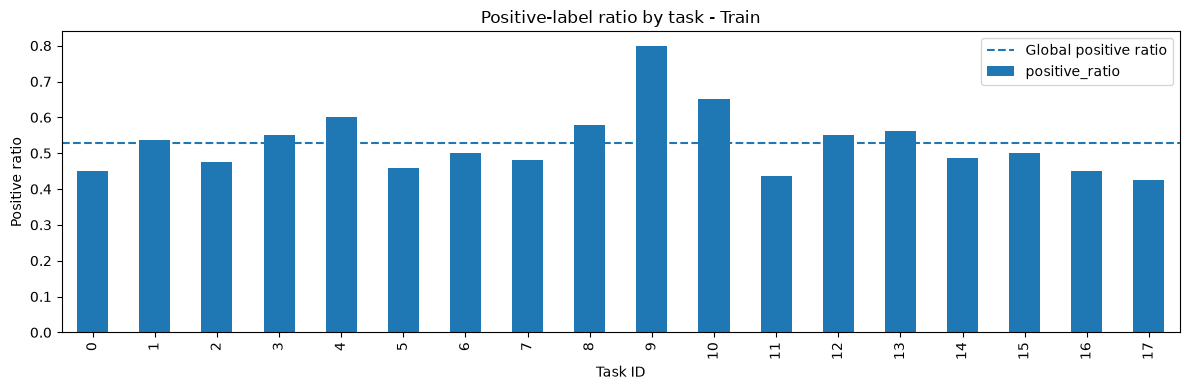

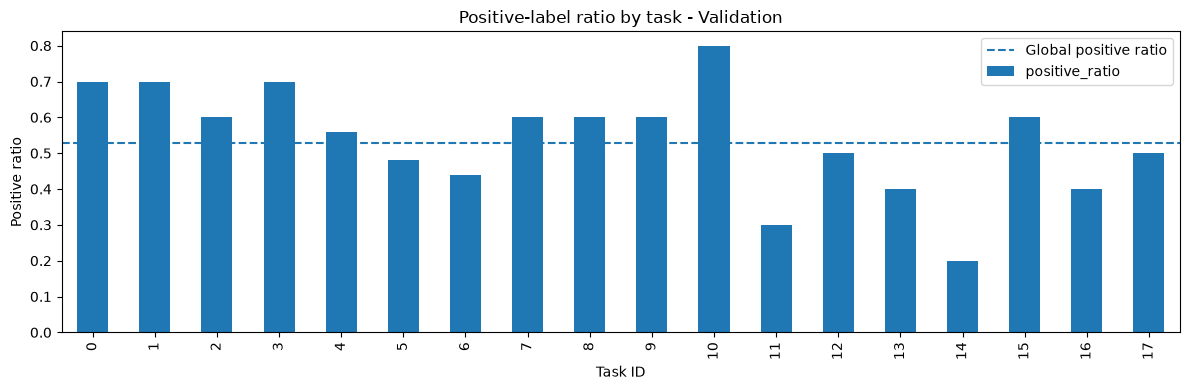

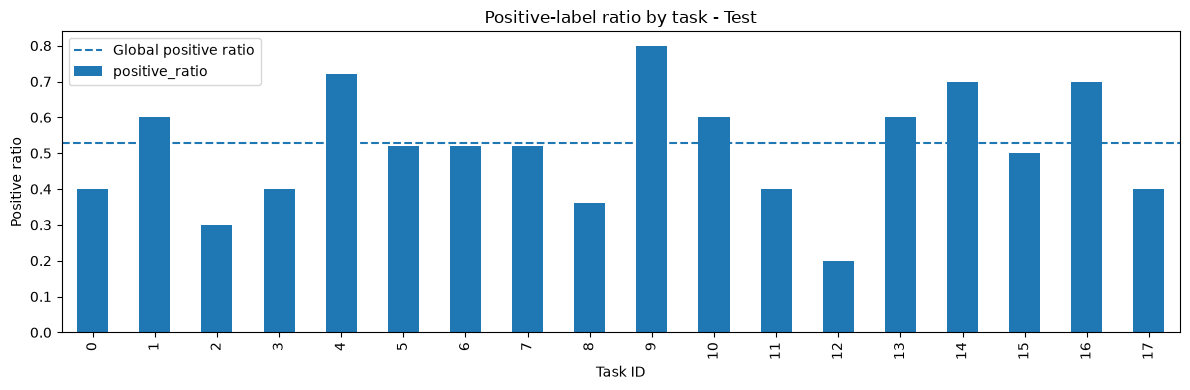

In [32]:
ax = task_labels_train["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Train",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a visualizzare il risultato.
#siccome la distribuzione degli esempi positivi tra i vari task varia,
#ed è spesso sbilanciata, dovremo utilizzare anche metriche diverse
#per valutare i modelli:
#precision, recall, F1


ax = task_labels_val["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Validation",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


ax = task_labels_test["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Test",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

### Parsing delle annotazioni simboliche

In [33]:
df_train["symbol_parsed"] = df_train["symbol"].apply(ast.literal_eval)
df_val["symbol_parsed"] = df_val["symbol"].apply(ast.literal_eval)
df_test["symbol_parsed"] = df_test["symbol"].apply(ast.literal_eval)
#nel dataset gli esempi sono costruiti a partire dal "symbol" ovvero:
#si hanno delle stringhe in un file yaml e tramite un generatore:
#
#qui andiamo a utilizzare ast per trasformare ciascuna stringa
#dizionario python, questo ci servirà per estrarre alcune
#statistiche importanti dai dati, in particolare:
#quante volte un certo concetto è stato utilizzato.

df_train[["filename", "task_id", "label", "symbol", "symbol_parsed"]].head()


,filename,task_id,label,symbol,symbol_parsed
0,0/0000.png,0,0,{'quadrant_ul': [{'diag_ll_ur': [{'shape': 'ci...,{'quadrant_ul': [{'diag_ll_ur': [{'shape': 'ci...
1,0/0001.png,0,1,{'quadrant_ur': [{'side_by_side': [{'shape': '...,{'quadrant_ur': [{'side_by_side': [{'shape': '...
2,0/0002.png,0,0,{'quadrant_ur': [{'diag_ul_lr': [{'shape': 'ci...,{'quadrant_ur': [{'diag_ul_lr': [{'shape': 'ci...
3,0/0003.png,0,1,"{'in': [{'side_by_side': [{'shape': 'circle', ...","{'in': [{'side_by_side': [{'shape': 'circle', ..."
4,0/0004.png,0,1,"{'in': [{'side_by_side': [{'shape': 'square', ...","{'in': [{'side_by_side': [{'shape': 'square', ..."


### Analisi dei concetti simbolici

In [34]:
def iter_objects(symbol):
    for position, objects in symbol.items():
        for obj in objects:
            yield position, obj

#funzione "comoda" che ci servira' dopo,
#prendiamo la lista delle descrizioni simboliche e,
#ogni volta che chiamiamo la funzione, questa
#ci restituisce "on the fly" la coppia position, object successiva

structure_counter = Counter()

for symbol in df_train["symbol_parsed"]:
    for position, objects in symbol.items():
        for obj in objects:
            structure_counter[tuple(sorted(obj.keys()))] += 1


for symbol in df_val["symbol_parsed"]:
    for position, objects in symbol.items():
        for obj in objects:
            structure_counter[tuple(sorted(obj.keys()))] += 1


for symbol in df_test["symbol_parsed"]:
    for position, objects in symbol.items():
        for obj in objects:
            structure_counter[tuple(sorted(obj.keys()))] += 1
#qui contiamo quante volte compare ogni struttura di attributi
#negli oggetti presenti nelle descrizioni simboliche.

print("Different object structures found:")
for structure, count in structure_counter.items():
    print(f"{count:4d} -> {structure}")


Different object structures found:
 735 -> ('diag_ll_ur',)
1156 -> ('side_by_side',)
 610 -> ('diag_ul_lr',)
1330 -> ('stack',)
  56 -> ('stack_reduce_bb',)
  58 -> ('side_by_side_reduce_bb',)
  46 -> ('grid',)
2198 -> ('color', 'shape', 'size')


=======TRAINSET=======
Shape counts: {'triangle': 599, 'circle': 598, 'square': 567}
Color counts: {'yellow': 296, 'red': 302, 'cyan': 306, 'green': 286, 'magenta': 278, 'blue': 296}
Size counts: {'small': 888, 'large': 876}
Position counts: {'quadrant_ul': 61, 'quadrant_ur': 71, 'in': 60, 'quadrant_lr': 62, 'quadrant_ll': 66, 'stack_reduce_bb': 129, 'diag_ll_ur': 1090, 'side_by_side_reduce_bb': 204, 'side_by_side': 198, 'diag_ul_lr': 1100, 'grid': 1071, 'stack': 241}


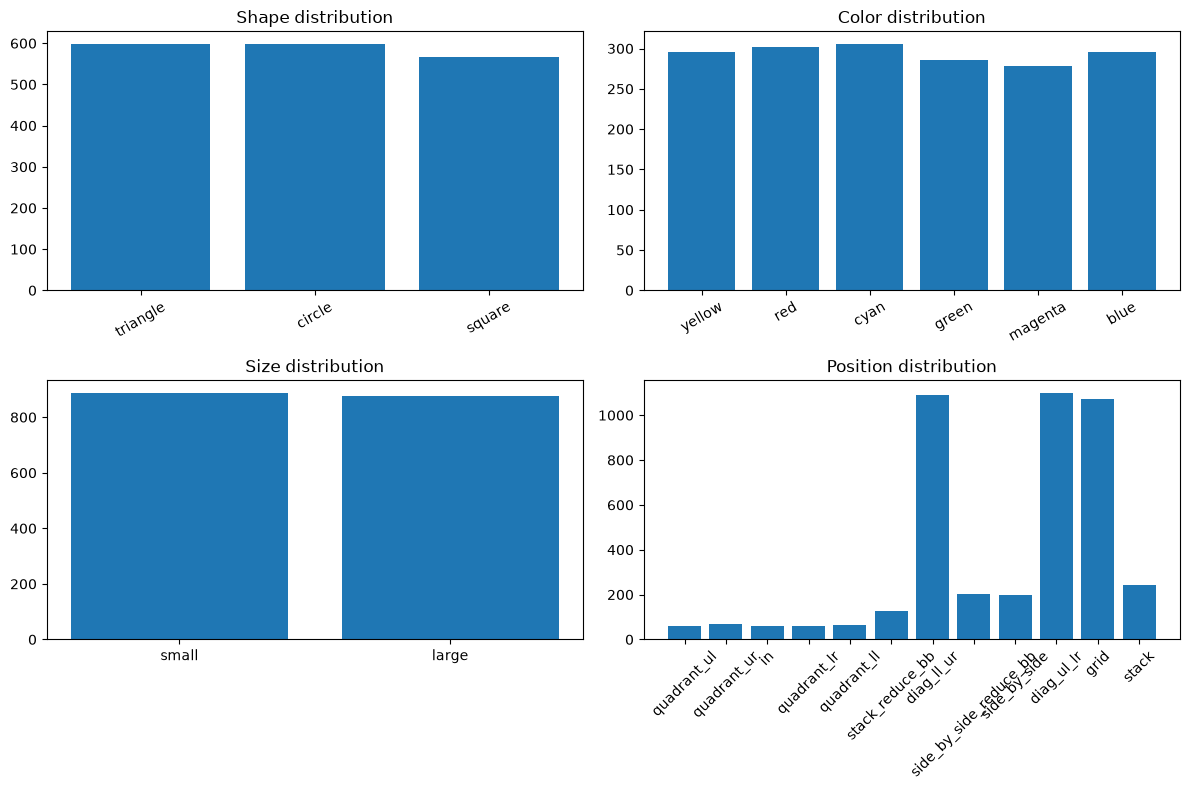

=======VALIDATIONSET=======
Shape counts: {'circle': 70, 'triangle': 75, 'square': 69}
Color counts: {'green': 31, 'cyan': 37, 'blue': 32, 'red': 28, 'yellow': 46, 'magenta': 40}
Size counts: {'small': 111, 'large': 103}
Position counts: {'quadrant_ur': 8, 'quadrant_ul': 5, 'quadrant_ll': 9, 'quadrant_lr': 9, 'in': 9, 'grid': 119, 'stack': 57, 'stack_reduce_bb': 30, 'diag_ll_ur': 284, 'diag_ul_lr': 309, 'side_by_side_reduce_bb': 36, 'side_by_side': 31}


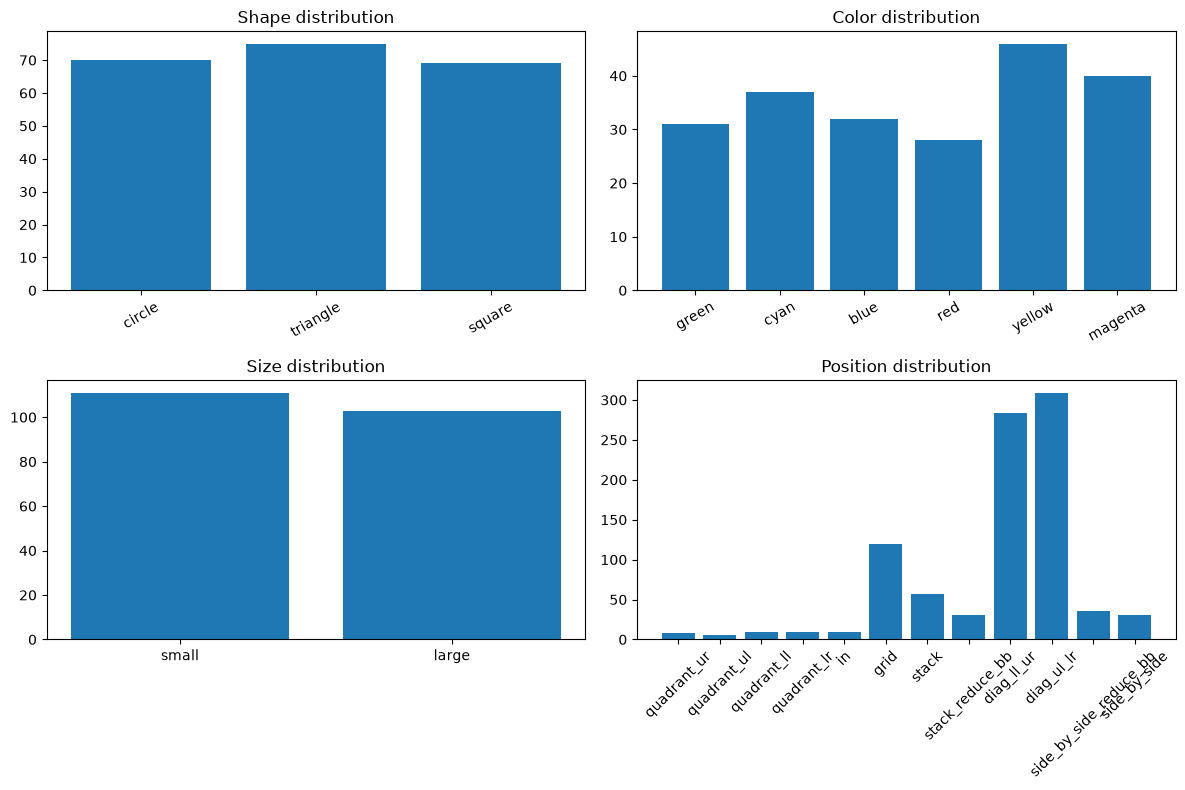

=======TESTSET=======
Shape counts: {'circle': 82, 'triangle': 71, 'square': 67}
Color counts: {'magenta': 39, 'green': 47, 'cyan': 26, 'red': 43, 'blue': 24, 'yellow': 41}
Size counts: {'large': 111, 'small': 109}
Position counts: {'quadrant_ul': 13, 'in': 11, 'quadrant_ll': 6, 'quadrant_lr': 5, 'quadrant_ur': 5, 'diag_ul_lr': 347, 'stack_reduce_bb': 55, 'side_by_side_reduce_bb': 43, 'diag_ll_ur': 241, 'stack': 44, 'grid': 155, 'side_by_side': 5}


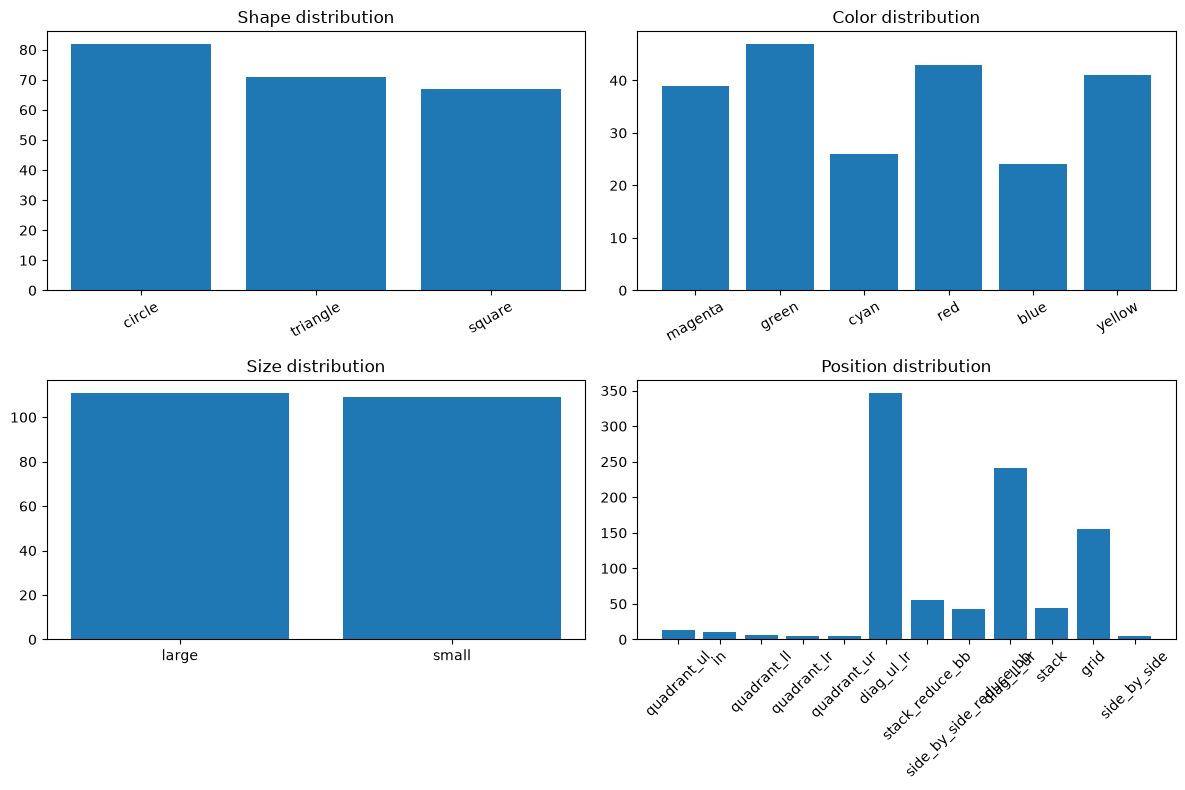

In [35]:
shape_counter = Counter()
color_counter = Counter()
size_counter = Counter()
position_counter = Counter()

for symbol in df_train["symbol_parsed"]:
    for position, obj in iter_objects(symbol):
        position_counter[position] += 1

        if "shape" in obj:
            shape_counter[obj["shape"]] += 1

        if "color" in obj:
            color_counter[obj["color"]] += 1

        if "size" in obj:
            size_counter[obj["size"]] += 1

#qui andiamo a estrarre tutte le descrizioni simboliche,
#dopodiché, utilizzando la funzione di prima, andiamo a
#estrarre uno a uno gli oggetti con la loro posizione

print("=======TRAINSET=======")
print("Shape counts:", dict(shape_counter))
print("Color counts:", dict(color_counter))
print("Size counts:", dict(size_counter))
print("Position counts:", dict(position_counter))

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

axes[0, 0].bar(
    shape_counter.keys(),
    shape_counter.values(),
)
axes[0, 0].set_title("Shape distribution")
axes[0, 0].tick_params(
    axis="x",
    rotation=30,
)

axes[0, 1].bar(
    color_counter.keys(),
    color_counter.values(),
)
axes[0, 1].set_title("Color distribution")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)

axes[1, 0].bar(
    size_counter.keys(),
    size_counter.values(),
)
axes[1, 0].set_title("Size distribution")

axes[1, 1].bar(
    position_counter.keys(),
    position_counter.values(),
)
axes[1, 1].set_title("Position distribution")
axes[1, 1].tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_properties_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close(fig)

shape_counter = Counter()
color_counter = Counter()
size_counter = Counter()
position_counter = Counter()
#reset dei contatori prima di analizzare il validation set

for symbol in df_val["symbol_parsed"]:
    for position, obj in iter_objects(symbol):
        position_counter[position] += 1

        if "shape" in obj:
            shape_counter[obj["shape"]] += 1

        if "color" in obj:
            color_counter[obj["color"]] += 1

        if "size" in obj:
            size_counter[obj["size"]] += 1

print("=======VALIDATIONSET=======")
print("Shape counts:", dict(shape_counter))
print("Color counts:", dict(color_counter))
print("Size counts:", dict(size_counter))
print("Position counts:", dict(position_counter))

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

axes[0, 0].bar(
    shape_counter.keys(),
    shape_counter.values(),
)
axes[0, 0].set_title("Shape distribution")
axes[0, 0].tick_params(
    axis="x",
    rotation=30,
)

axes[0, 1].bar(
    color_counter.keys(),
    color_counter.values(),
)
axes[0, 1].set_title("Color distribution")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)

axes[1, 0].bar(
    size_counter.keys(),
    size_counter.values(),
)
axes[1, 0].set_title("Size distribution")

axes[1, 1].bar(
    position_counter.keys(),
    position_counter.values(),
)
axes[1, 1].set_title("Position distribution")
axes[1, 1].tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_properties_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close(fig)

shape_counter = Counter()
color_counter = Counter()
size_counter = Counter()
position_counter = Counter()
#reset dei contatori prima di analizzare il test set

for symbol in df_test["symbol_parsed"]:
    for position, obj in iter_objects(symbol):
        position_counter[position] += 1

        if "shape" in obj:
            shape_counter[obj["shape"]] += 1

        if "color" in obj:
            color_counter[obj["color"]] += 1

        if "size" in obj:
            size_counter[obj["size"]] += 1

print("=======TESTSET=======")
print("Shape counts:", dict(shape_counter))
print("Color counts:", dict(color_counter))
print("Size counts:", dict(size_counter))
print("Position counts:", dict(position_counter))

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
)

axes[0, 0].bar(
    shape_counter.keys(),
    shape_counter.values(),
)
axes[0, 0].set_title("Shape distribution")
axes[0, 0].tick_params(
    axis="x",
    rotation=30,
)

axes[0, 1].bar(
    color_counter.keys(),
    color_counter.values(),
)
axes[0, 1].set_title("Color distribution")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)

axes[1, 0].bar(
    size_counter.keys(),
    size_counter.values(),
)
axes[1, 0].set_title("Size distribution")

axes[1, 1].bar(
    position_counter.keys(),
    position_counter.values(),
)
axes[1, 1].set_title("Position distribution")
axes[1, 1].tick_params(
    axis="x",
    rotation=45,
)

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_properties_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close(fig)

### Numero di oggetti per immagine

In [36]:
def count_objects(symbol):
    return sum(len(objects) for objects in symbol.values())
#questa funzione ci permette di ottenere il numero totale di oggetti per descrizione simbolica

print("=======TRAINING=======")
df_train["num_objects"] = df_train["symbol_parsed"].apply(count_objects)
#andiamo a contare per ciascuna entrata
print(df_train["num_objects"].describe())
#otteniamo alcune statistiche: la maggior parte dei task ha 1 oggetto,
#il task col maggior numero ne ha 6

print("=======VAL=======")
df_val["num_objects"] = df_val["symbol_parsed"].apply(count_objects)
print(df_val["num_objects"].describe())

print("=======TEST=======")
df_test["num_objects"] = df_test["symbol_parsed"].apply(count_objects)
print(df_test["num_objects"].describe())

=======TRAINING=======
count    1290.000000
mean        3.374419
std         1.831996
min         1.000000
25%         2.000000
50%         4.000000
75%         4.000000
max         7.000000
Name: num_objects, dtype: float64
=======VAL=======
count    255.000000
mean       3.552941
std        1.454067
min        1.000000
25%        3.000000
50%        4.000000
75%        4.000000
max        7.000000
Name: num_objects, dtype: float64
=======TEST=======
count    255.000000
mean       3.647059
std        1.447555
min        1.000000
25%        4.000000
50%        4.000000
75%        4.000000
max        7.000000
Name: num_objects, dtype: float64


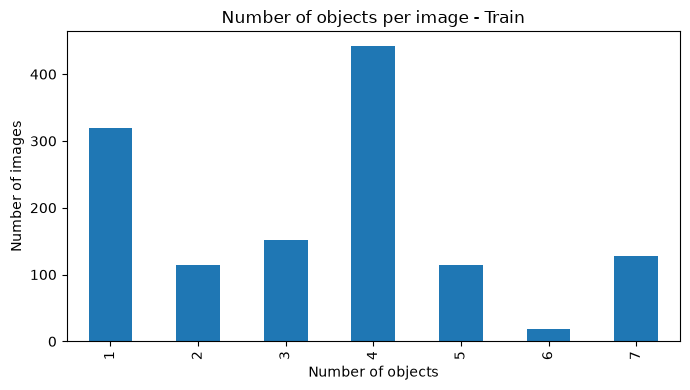

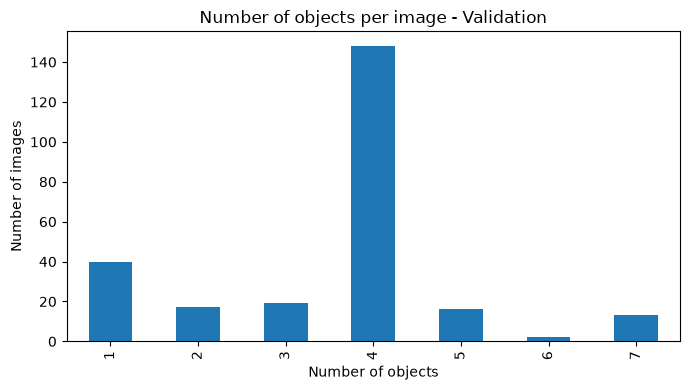

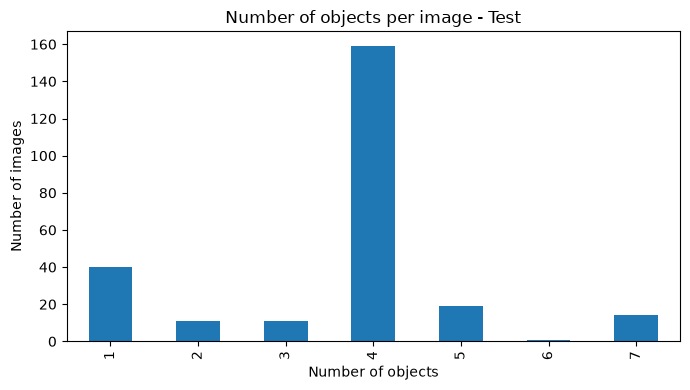

In [37]:
object_counts = (
    df_train["num_objects"]
    .value_counts()
    .sort_index()
)

ax = object_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of objects per image - Train",
)

ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_count_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()


object_counts = (
    df_val["num_objects"]
    .value_counts()
    .sort_index()
)

ax = object_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of objects per image - Validation",
)

ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_count_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


object_counts = (
    df_test["num_objects"]
    .value_counts()
    .sort_index()
)

ax = object_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="Number of objects per image - Test",
)

ax.set_xlabel("Number of objects")
ax.set_ylabel("Number of images")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "object_count_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

#la maggior parte degli esempi ha un solo oggetto.

### Estrazione dei concetti interpretabili

In [38]:
def extract_concepts(symbol):
    objects = list(iter_objects(symbol))

    if not objects:
        return {
            "position": None,
            "shape": None,
            "color": None,
            "size": None,
            "num_objects": 0,
        }

    position, obj = objects[0]

    return {
        "position": position,
        "shape": obj.get("shape"),
        "color": obj.get("color"),
        "size": obj.get("size"),
        "num_objects": len(objects),
    }
#questa funzione serve per, data una descrizione simbolica ottenerne
#i concetti interpretabili, estrarne alcune proprietà
#interpretabili dell'oggetto e il numero totale di oggetti presenti.

concepts = df_train["symbol_parsed"].apply(extract_concepts)
#otteniamo dizionario concetti
concept_df = pd.DataFrame(concepts.tolist())
#li uniamo in una lista di dizionari, e facciamo diventare le chiavi dizionari
#delle colonne di un dataframe

df_concepts = pd.concat(
    [
        df_train[["filename", "task_id", "label"]].reset_index(drop=True),
        concept_df.reset_index(drop=True),
    ],
    axis=1,
)
#a questo affianchiamo le colonne ottenute dal dataframe, accanto a quelle originali.


df_concepts.head(200)


,filename,task_id,label,position,shape,color,size,num_objects
0,0/0000.png,0,0,quadrant_ul,NaN,NaN,NaN,1
1,0/0001.png,0,1,quadrant_ur,NaN,NaN,NaN,1
2,0/0002.png,0,0,quadrant_ur,NaN,NaN,NaN,1
3,0/0003.png,0,1,in,NaN,NaN,NaN,1
4,0/0004.png,0,1,in,NaN,NaN,NaN,1
...,...,...,...,...,...,...,...,...
195,2/0035.png,2,1,quadrant_ur,NaN,NaN,NaN,1
196,2/0036.png,2,1,quadrant_lr,NaN,NaN,NaN,1
197,2/0037.png,2,1,quadrant_ll,NaN,NaN,NaN,1
198,2/0038.png,2,1,in,NaN,NaN,NaN,1


### Visualizzazione delle immagini

Image path: /home/cosimo/progetti/tesi/data/hard/samples/sets/train/0/0000.png
Image size: (224, 224)
Task: 0
Label: 0
Symbol: {'quadrant_ul': [{'diag_ll_ur': [{'shape': 'circle', 'color': 'yellow', 'size': 'small'}, {'shape': 'circle', 'color': 'red', 'size': 'large'}]}]}


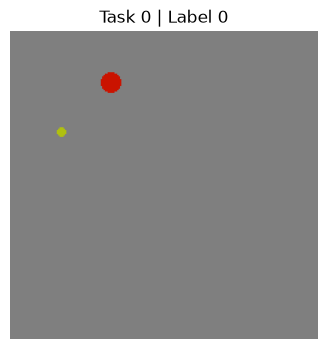

In [39]:
sample = df_train.iloc[0]
#accedo al dataframe di train e prendo la prima riga (prima immagine)

img_path = TRAIN_DIR / sample["filename"]
img = Image.open(img_path)

print("Image path:", img_path)
print("Image size:", img.size)
print("Task:", sample["task_id"])
print("Label:", sample["label"])
print("Symbol:", sample["symbol"])

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis("off")
plt.title(f"Task {sample.task_id} | Label {sample.label}")
plt.show()
#plottiamo task, label, concetti interpretabili contenuti nell'immagine e l'immagine

### Esempi positivi e negativi con descrizione

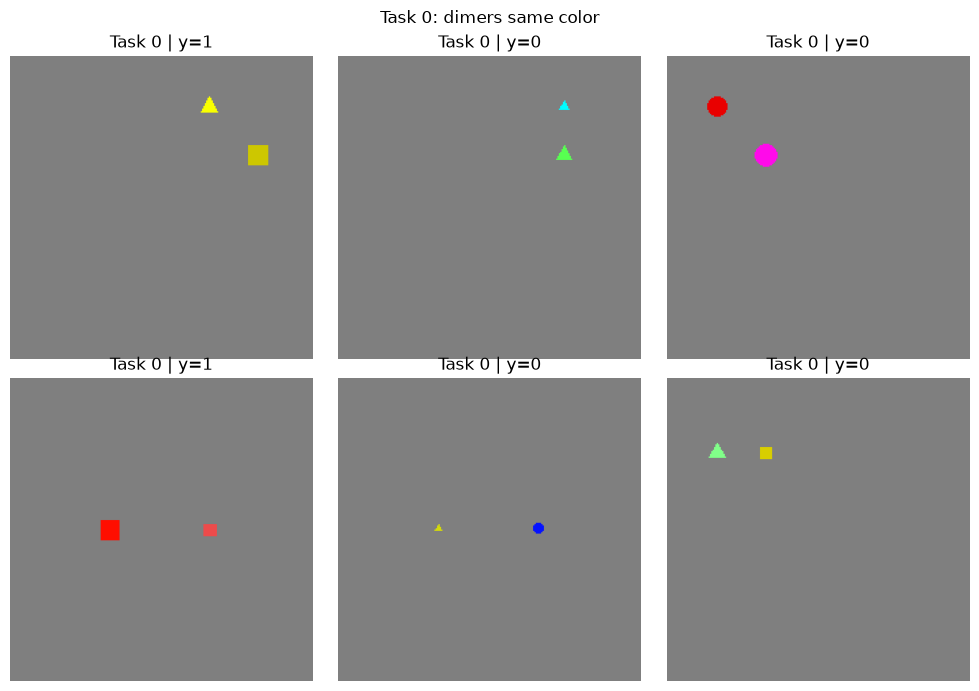

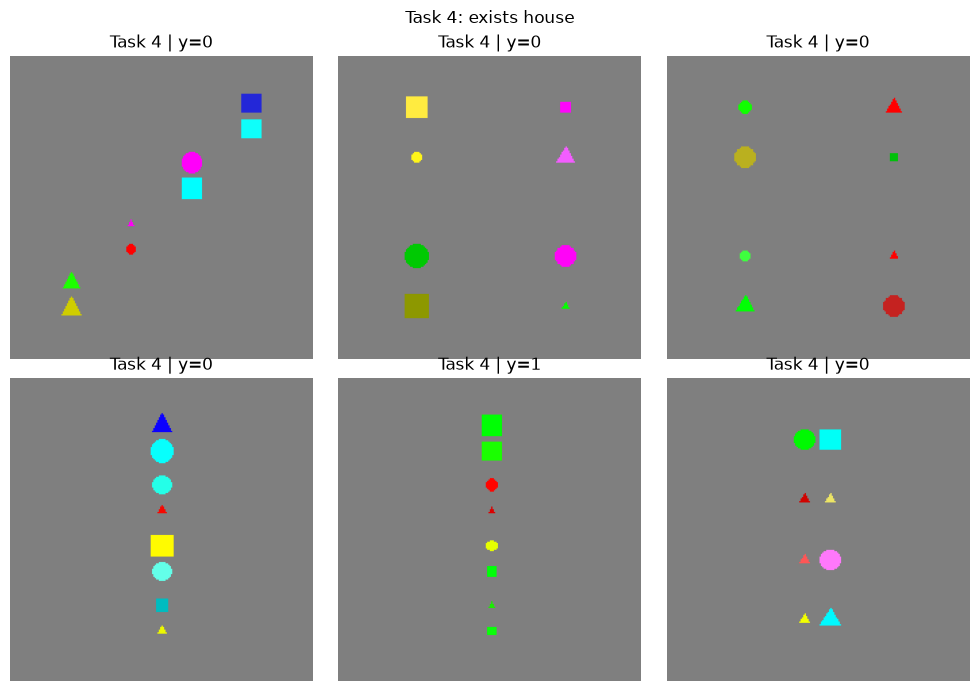

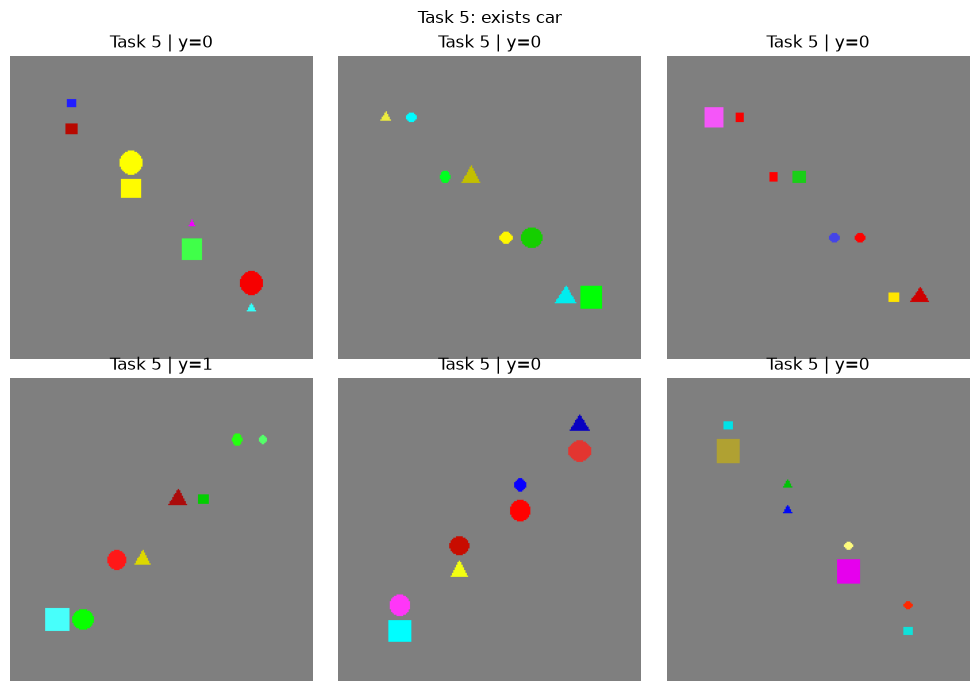

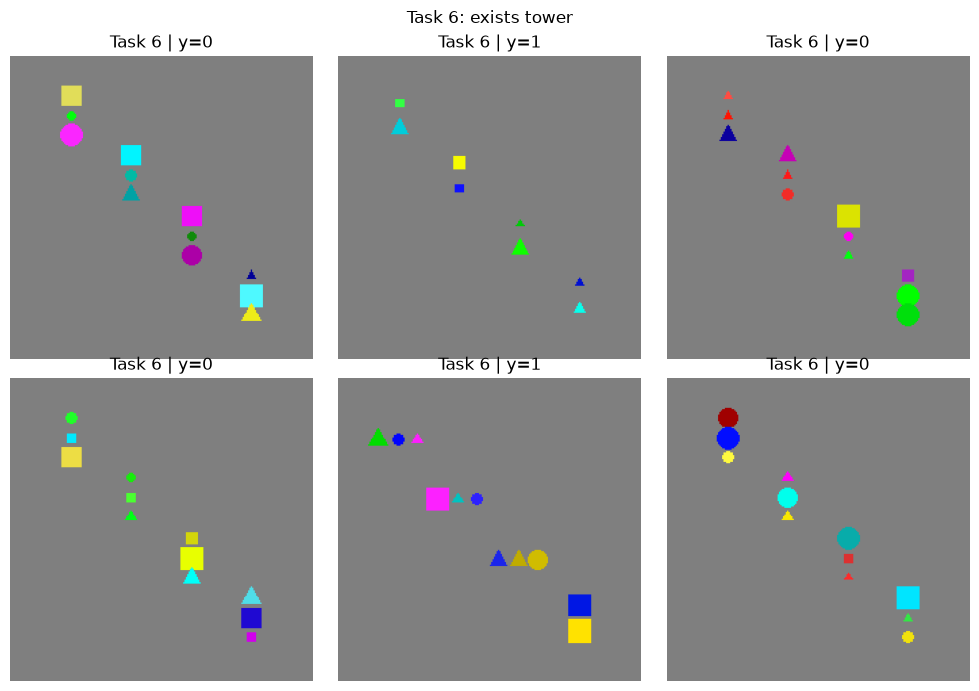

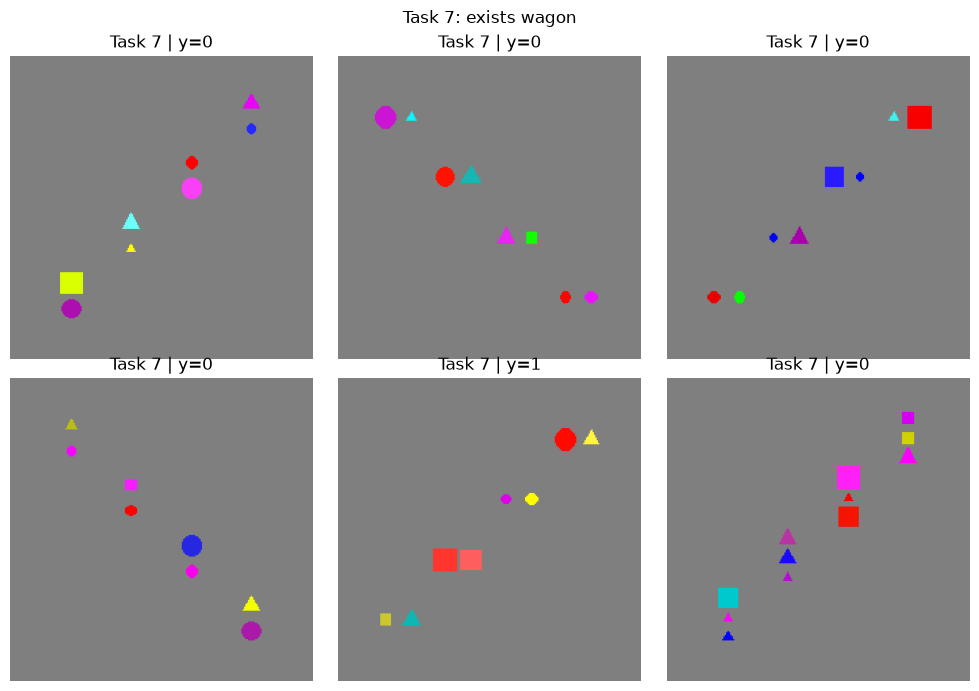

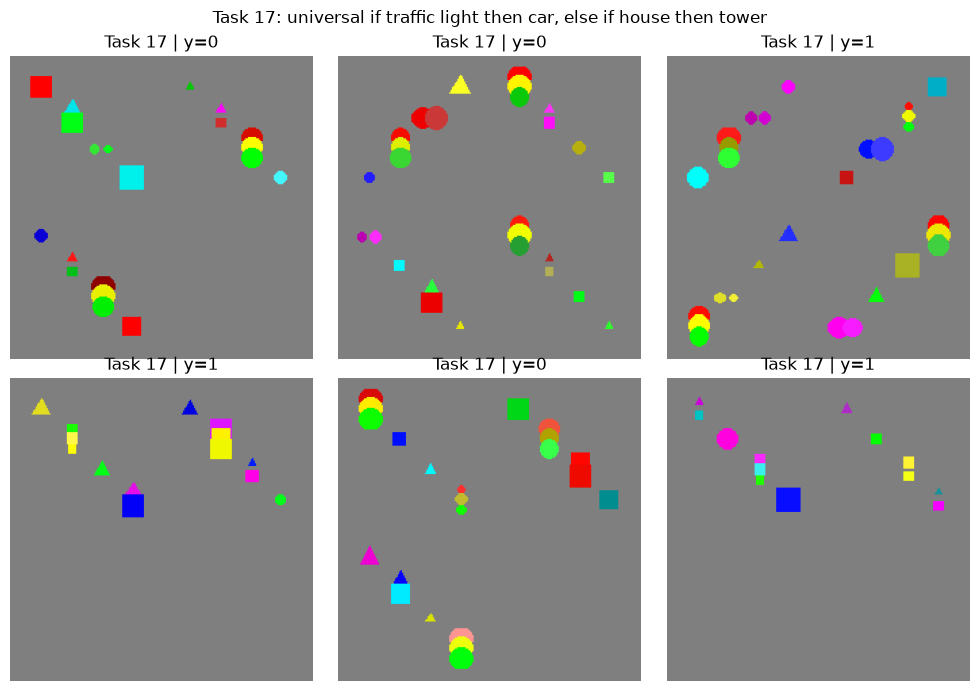

In [43]:
task_names = {
    0: "dimers same color",
    1: "dimers same shape",
    2: "trimers same color",
    3: "trimers same shape",
    4: "exists house",
    5: "exists car",
    6: "exists tower",
    7: "exists wagon",
    8: "traffic light",
    9: "for each group exists shared shape",
    10: "for each group exists shared color",
    11: "for each group exists shared named object",
    12: "flat palindromes",
    13: "pseudo palindrome",
    14: "pseudo palindrome with named objects",
    15: "odd same color even same shape",
    16: "if traffic light then car, else if house then tower",
    17: "universal if traffic light then car, else if house then tower",
}

def show_task_examples(df, task_id, n=6, seed=123):
    subset = df[df["task_id"] == task_id]
    samples = subset.sample(n=min(n, len(subset)), random_state=seed)

    fig, axes = plt.subplots(2, 3, figsize=(10, 7))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, samples.iterrows()):
        img = Image.open(TRAIN_DIR / row["filename"])
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"Task {row.task_id} | y={row.label}")

    fig.suptitle(f"Task {task_id}: {task_names[task_id]}")
    plt.tight_layout()

    fig.savefig(
        PLOTS_DIR / f"task_{task_id}_examples.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
    #salva l'immagine e chiude la figura

for task_id in [0, 4, 5, 6, 7, 17]:
    show_task_examples(df_train, task_id)
#plottiamo e salviamo alcuni esempi per i task selezionati

### Panoramica delle task

In [ ]:
task_overview = task_labels_train.copy()
task_overview["task_name"] = task_overview.index.map(task_names)

task_overview[
    ["task_name", "total", "positives", "negatives", "positive_ratio"]
]

#piccolo riassunto finale.

### Conclusioni KANDY-HARD

Il dataset contiene dunque:

- 1290 immagini di training;
- 18 task di classificazione binaria;
- dai 50 agli 80 campioni di training per task;
- annotazioni simboliche che descrivono le scene;
- concetti interpretabili come forma, colore, dimensione e posizione;
- regole logiche differenti tra le task.

La baseline globale ottenuta considerando il modello che predice la classe maggioritaria è circa 52,8%

In [ ]:
task_labels_train = (
    df_train.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
)
#raggruppo il dataset per task_id e vado a contare le label per ciascun task (50 per task come avevamo visto prima)
#e aggiungo due colonne 

task_labels_train["negatives"] = task_labels_train["total"] - task_labels_train["positives"]
task_labels_train["positive_ratio"] = task_labels_train["positives"] / task_labels_train["total"]
#vado a calcolare n_label_positive, n_label_negative e il rapporto tra esempi positivi ed esempi totali

print(task_labels_train)
#si noti che su quasi tutti i casi il numero di esempi positivi è strettamente minore di quelli negativi,
#nel task 19 (semaforo), abbiamo che solo il 10% degli esempi è positivo

task_labels_val = (
    df_val.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
) 

task_labels_val["negatives"] = task_labels_val["total"] - task_labels_val["positives"]
task_labels_val["positive_ratio"] = task_labels_val["positives"] / task_labels_val["total"]

print(task_labels_val)


task_labels_test = (
    df_test.groupby("task_id")["label"]
    .agg(total="count", positives="sum")
)

task_labels_test["negatives"] = task_labels_test["total"] - task_labels_test["positives"]
task_labels_test["positive_ratio"] = task_labels_test["positives"] / task_labels_test["total"]

print(task_labels_test)

In [ ]:
ax = task_labels_train["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Train",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_train.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del training set

plt.show()
plt.close()

#andiamo a visualizzare il risultato.
#siccome la distribuzione degli esempi positivi tra i vari task varia,
#ed è spesso sbilanciata, dovremo utilizzare anche metriche diverse
#per valutare i modelli:
#precision, recall, F1


ax = task_labels_val["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Validation",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_val.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del validation set

plt.show()
plt.close()


ax = task_labels_test["positive_ratio"].plot(
    kind="bar",
    figsize=(12, 4),
    title="Positive-label ratio by task - Test",
)
ax.set_xlabel("Task ID")
ax.set_ylabel("Positive ratio")

plt.axhline(
    df_train["label"].mean(),
    linestyle="--",
    label="Global positive ratio",
)

plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "positive_ratio_test.png",
    dpi=200,
    bbox_inches="tight",
)
#salva il plot del test set

plt.show()
plt.close()

## KANDY BONGARD

In [45]:
#controlliamo la struttura del dataset KANDY-Bongard

DATASET_ROOT = PROJECT_ROOT / "data"

#individuiamo la cartella contenente le tre rappresentazioni
dataset_dirs = [
    p.parent for p in DATASET_ROOT.rglob("foundalis_100")
    if all((p.parent / folder).is_dir()
           for folder in ["foundalis_100", "foundalis_224", "grid"])
]

if not dataset_dirs:
    raise FileNotFoundError("Cartella del dataset KANDY-Bongard non trovata.")

if len(dataset_dirs) > 1:
    raise RuntimeError("Trovate più cartelle del dataset. Specificare il percorso.")

dataset_path = dataset_dirs[0]

print("Dataset:", dataset_path)

#analizziamo le tre rappresentazioni
for folder in ["foundalis_100", "foundalis_224", "grid"]:

    images = sorted((dataset_path / folder).glob("*.png"))

    easy = [img for img in images if img.stem.startswith("easy-")]
    hard = [img for img in images if img.stem.startswith("hard-")]

    dimensions = Counter()

    for image_path in images:
        with Image.open(image_path) as img:
            dimensions[img.size] += 1

    print(f"\n{folder}")
    print(f"Easy: {len(easy)}")
    print(f"Hard: {len(hard)}")
    print(f"Totale: {len(images)}")
    print(f"Dimensioni: {dict(dimensions)}")

Dataset: /home/cosimo/progetti/tesi/data/kandy-bongard

foundalis_100
Easy: 20
Hard: 18
Totale: 38
Dimensioni: {(516, 330): 38}

foundalis_224
Easy: 20
Hard: 18
Totale: 38
Dimensioni: {(1156, 739): 38}

grid
Easy: 20
Hard: 18
Totale: 38
Dimensioni: {(453, 1358): 38}


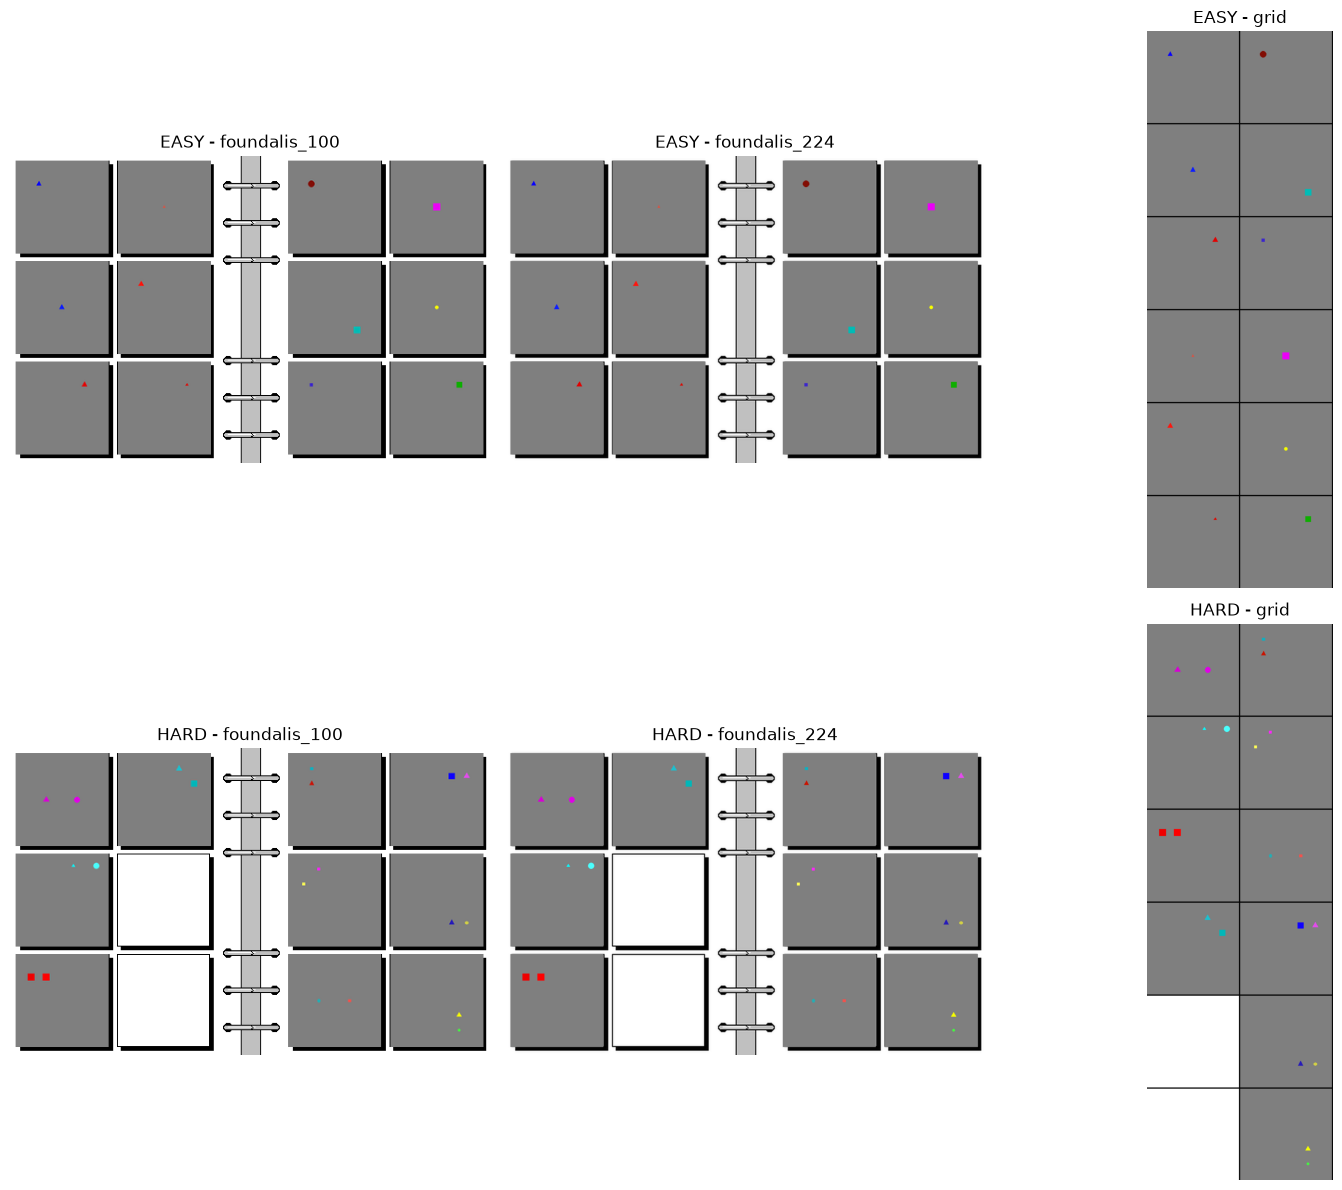

In [46]:
#visualizziamo alcuni esempi nelle tre rappresentazioni

representations = ["foundalis_100", "foundalis_224", "grid"]

fig, axes = plt.subplots(2, 3, figsize=(15, 12))

for row, level in enumerate(["easy", "hard"]):
    for col, representation in enumerate(representations):

        image_path = dataset_path / representation / f"{level}-0.png"

        img = Image.open(image_path)

        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{level.upper()} - {representation}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

Siccome potrebbero essere utili per esperimenti futuri, creo delle cartelle con i singoli esempi presenti nei fondali.

In [48]:
#ricerchiamo le immagini originali KANDY utilizzate nei problemi Bongard
import hashlib

#costruiamo un indice delle immagini originali tramite hash
original_images = {}

for dataset in ["easy", "hard"]:
    for split in ["train", "val", "test"]:

        split_dir = PROJECT_ROOT / "data" / dataset / "samples" / "sets" / split
        csv_path = split_dir / "annotations.csv"

        if not csv_path.exists():
            print(f"Attenzione: {csv_path} non trovato")
            continue

        annotations = pd.read_csv(csv_path)

        for _, row in annotations.iterrows():

            image_path = split_dir / row["filename"]

            if not image_path.exists():
                continue

            with Image.open(image_path) as img:
                img = img.convert("RGB")

                if img.size != (224, 224):
                    continue

                image_hash = hashlib.sha256(img.tobytes()).hexdigest()

            record = {
                "dataset": dataset,
                "split": split,
                "filename": row["filename"],
                "task_id": row["task_id"],
                "label": row["label"],
                "symbol": row["symbol"]
            }

            original_images.setdefault(image_hash, []).append(record)

print(f"Immagini originali indicizzate: {sum(len(v) for v in original_images.values())}")

#definiamo le coordinate dei 12 riquadri nella rappresentazione Foundalis 224
x_positions = {
    "positive": [13, 259],
    "negative": [669, 915]
}

y_positions = [11, 253, 495]

#cerchiamo le immagini originali di ogni problema
matches = []

for level, n_tasks in [("easy", 20), ("hard", 18)]:

    for problem_id in range(n_tasks):

        image_path = dataset_path / "foundalis_224" / f"{level}-{problem_id}.png"

        with Image.open(image_path) as board:
            board = board.convert("RGB")

            for side, x_values in x_positions.items():

                for y in y_positions:
                    for x in x_values:

                        crop = board.crop((x, y, x + 224, y + 224))
                        image_hash = hashlib.sha256(crop.tobytes()).hexdigest()

                        found = original_images.get(image_hash, [])

                        matches.append({
                            "problema": f"{level}-{problem_id}",
                            "lato": side,
                            "file_originale": [
                                m["filename"] for m in found
                            ],
                            "dataset_originale": [
                                m["dataset"] for m in found
                            ],
                            "split_originale": [
                                m["split"] for m in found
                            ],
                            "task_id_originale": [
                                m["task_id"] for m in found
                            ],
                            "label_originale": [
                                m["label"] for m in found
                            ],
                            "symbol": [
                                m["symbol"] for m in found
                            ],
                            "match_esatto": len(found) > 0,
                            "label_coerente": (
                                len(found) > 0 and
                                all(
                                    int(m["label"]) == (1 if side == "positive" else 0)
                                    for m in found
                                )
                            )
                        })

#creiamo un dataframe con i risultati
matches_df = pd.DataFrame(matches)

print("\nRISULTATI DEL MATCHING")
print(f"Riquadri analizzati: {len(matches_df)}")
print(f"Corrispondenze esatte: {matches_df['match_esatto'].sum()}")
print(f"Immagini non individuate: {(~matches_df['match_esatto']).sum()}")

display(matches_df.head(24))

Immagini originali indicizzate: 3800

RISULTATI DEL MATCHING
Riquadri analizzati: 456
Corrispondenze esatte: 419
Immagini non individuate: 37


,problema,lato,file_originale,dataset_originale,split_originale,task_id_originale,label_originale,symbol,match_esatto,label_coerente
0,easy-0,positive,[0/0000.png],[easy],[test],[0],[1],"[{'quadrant_ul': [{'shape': 'triangle', 'color...",True,True
1,easy-0,positive,[0/0006.png],[easy],[test],[0],[1],"[{'in': [{'shape': 'triangle', 'color': 'red',...",True,True
2,easy-0,positive,[0/0001.png],[easy],[test],[0],[1],"[{'in': [{'shape': 'triangle', 'color': 'blue'...",True,True
3,easy-0,positive,[0/0007.png],[easy],[test],[0],[1],"[{'quadrant_ul': [{'shape': 'triangle', 'color...",True,True
4,easy-0,positive,[0/0003.png],[easy],[test],[0],[1],"[{'quadrant_ur': [{'shape': 'triangle', 'color...",True,True
5,easy-0,positive,[0/0010.png],[easy],[test],[0],[1],"[{'quadrant_ur': [{'shape': 'triangle', 'color...",True,True
6,easy-0,negative,[0/0002.png],[easy],[test],[0],[0],"[{'quadrant_ul': [{'shape': 'circle', 'color':...",True,True
7,easy-0,negative,[0/0008.png],[easy],[test],[0],[0],"[{'in': [{'shape': 'square', 'color': 'magenta...",True,True
8,easy-0,negative,[0/0004.png],[easy],[test],[0],[0],"[{'quadrant_lr': [{'shape': 'square', 'color':...",True,True
9,easy-0,negative,[0/0009.png],[easy],[test],[0],[0],"[{'in': [{'shape': 'circle', 'color': 'yellow'...",True,True


In [61]:
#ricostruiamo i fondali foundalis_100 utilizzando direttamente il test set di KANDY

import shutil

#definiamo la cartella di destinazione
output_root = dataset_path / "foundalis_224" / "decomp"

#ricreiamo la cartella da zero
if output_root.exists():
    shutil.rmtree(output_root)

output_root.mkdir(parents=True, exist_ok=True)

#analizziamo Easy e Hard
for level, n_tasks in [("easy", 20), ("hard", 18)]:

    test_dir = PROJECT_ROOT / "data" / level / "samples" / "sets" / "test"
    annotations = pd.read_csv(test_dir / "annotations.csv")

    #selezioniamo gli esempi per ciascun task
    for task_id in range(n_tasks):

        task = annotations[annotations["task_id"] == task_id]

        positive = task[task["label"] == 1].head(6)
        negative = task[task["label"] == 0].head(6)

        #creiamo la cartella del fondale
        problem_name = f"{level}-{task_id}"
        problem_dir = output_root / problem_name
        problem_dir.mkdir(parents=True, exist_ok=True)

        #copiamo il fondale originale
        board_path = dataset_path / "foundalis_224" / f"{problem_name}.png"
        shutil.copy2(board_path, problem_dir / "grid_originale.png")

        #copiamo i sei esempi positivi e negativi
        for side, samples in [("positive", positive), ("negative", negative)]:

            for i, (_, row) in enumerate(samples.iterrows(), start=1):

                source = test_dir / row["filename"]
                destination = problem_dir / f"{side}_{i:02d}{source.suffix}"

                shutil.copy2(source, destination)

        print(f"{problem_name}: {len(positive)} positivi, {len(negative)} negativi")

print(f"\nCartelle create: {n_tasks if False else 38}")
print(f"Percorso: {output_root}")

easy-0: 6 positivi, 6 negativi
easy-1: 6 positivi, 6 negativi
easy-2: 6 positivi, 6 negativi
easy-3: 6 positivi, 6 negativi
easy-4: 6 positivi, 6 negativi
easy-5: 6 positivi, 6 negativi
easy-6: 6 positivi, 6 negativi
easy-7: 6 positivi, 6 negativi
easy-8: 5 positivi, 6 negativi
easy-9: 6 positivi, 6 negativi
easy-10: 6 positivi, 6 negativi
easy-11: 6 positivi, 6 negativi
easy-12: 6 positivi, 6 negativi
easy-13: 6 positivi, 6 negativi
easy-14: 6 positivi, 6 negativi
easy-15: 6 positivi, 6 negativi
easy-16: 6 positivi, 6 negativi
easy-17: 6 positivi, 6 negativi
easy-18: 6 positivi, 6 negativi
easy-19: 3 positivi, 6 negativi
hard-0: 4 positivi, 6 negativi
hard-1: 6 positivi, 4 negativi
hard-2: 3 positivi, 6 negativi
hard-3: 4 positivi, 6 negativi
hard-4: 6 positivi, 6 negativi
hard-5: 6 positivi, 6 negativi
hard-6: 6 positivi, 6 negativi
hard-7: 6 positivi, 6 negativi
hard-8: 6 positivi, 6 negativi
hard-9: 6 positivi, 2 negativi
hard-10: 6 positivi, 4 negativi
hard-11: 4 positivi, 6 negat

## BONGARD RWR+

### Download del dataset

In [ ]:
#scarichiamo il dataset Bongard-RWR+
from huggingface_hub import snapshot_download

#definiamo la cartella di destinazione
rwr_root = PROJECT_ROOT / "data" / "bongard-rwr-plus"
rwr_root.mkdir(parents=True, exist_ok=True)

#scarichiamo il repository hugging Face
snapshot_download(
    repo_id="bongard-rwr-plus/bongard-rwr-plus",
    repo_type="dataset",
    local_dir=str(rwr_root)
)

print(f"Dataset scaricato in: {rwr_root}")

### Struttura del dataset

In [62]:
#controlliamo la struttura del dataset Bongard-RWR+

import json
from collections import Counter

#definiamo la cartella del dataset
rwr_root = PROJECT_ROOT / "data" / "bongard-rwr-plus"

if not rwr_root.exists():
    raise FileNotFoundError(f"Dataset non trovato: {rwr_root}")

#analizziamo le cartelle e il numero di file
print("Cartella dataset:", rwr_root)

for folder in ["images", "lefts", "rights", "wholes"]:

    folder_path = rwr_root / folder

    if folder_path.exists():
        files = [f for f in folder_path.rglob("*") if f.is_file()]

        extensions = Counter(f.suffix.lower() for f in files)

        print(f"\n{folder}")
        print(f"File totali: {len(files)}")
        print(f"Estensioni: {dict(extensions)}")
    else:
        print(f"\nCartella {folder} non trovata")

#carichiamo i metadati
metadata_path = rwr_root / "dataset.json"

if not metadata_path.exists():
    raise FileNotFoundError("File dataset.json non trovato")

with open(metadata_path, "r", encoding="utf-8") as f:
    rwr_data = json.load(f)

#verifichiamo la struttura del file JSON
print("\nSTRUTTURA METADATI")
print("Tipo:", type(rwr_data).__name__)

if isinstance(rwr_data, list):
    rwr_records = rwr_data

elif isinstance(rwr_data, dict):
    print("Chiavi principali:", list(rwr_data.keys()))

    rwr_records = None

    for key in ["problems", "data", "instances", "records"]:
        if isinstance(rwr_data.get(key), list):
            rwr_records = rwr_data[key]
            print("Lista dei problemi:", key)
            break

    if rwr_records is None:
        rwr_records = list(rwr_data.values())

else:
    raise ValueError("Struttura JSON non riconosciuta")

print("\nNumero di record:", len(rwr_records))

#esaminiamo il primo problema
if rwr_records:
    sample = rwr_records[0]

    print("\nPRIMO PROBLEMA")
    for key, value in sample.items():

        if isinstance(value, list):
            print(f"{key}: {len(value)} elementi")
            print("Esempio:", value[:2])
        else:
            print(f"{key}: {value}")

Cartella dataset: /home/cosimo/progetti/tesi/data/bongard-rwr-plus

images
File totali: 4157
Estensioni: {'.jpg': 4157}

lefts
File totali: 5400
Estensioni: {'.jpg': 5400}

rights
File totali: 5400
Estensioni: {'.jpg': 5400}

wholes
File totali: 5400
Estensioni: {'.jpg': 5400}

STRUTTURA METADATI
Tipo: dict
Chiavi principali: ['problems']
Lista dei problemi: problems

Numero di record: 5400

PRIMO PROBLEMA
id: 1
left_images: 7 elementi
Esempio: ['images/0.jpg', 'images/1.jpg']
right_images: 7 elementi
Esempio: ['images/7.jpg', 'images/8.jpg']
left_side_image: lefts/1.jpg
right_side_image: rights/1.jpg
whole_image: wholes/1.jpg
left_concept: Empty picture
right_concept: Not empty picture
concept_group: Count
diversity: 0.172


### Distribuzione dei concetti e dei problemi

In [63]:
#analizziamo la distribuzione dei concetti e dei problemi

rwr_df = pd.DataFrame(rwr_records)

#analizziamo gli identificativi
print("PROBLEMI")
print(f"Numero di problemi: {len(rwr_df)}")
print(f"ID distinti: {rwr_df['id'].nunique()}")
print(f"ID duplicati: {rwr_df['id'].duplicated().sum()}")
print(f"ID minimo: {rwr_df['id'].min()}")
print(f"ID massimo: {rwr_df['id'].max()}")

#analizziamo la distribuzione dei gruppi concettuali
print("\nGRUPPI CONCETTUALI")
display(rwr_df["concept_group"].value_counts().to_frame("Problemi"))

#analizziamo le coppie di concetti
concept_pairs = (
    rwr_df.groupby(
        ["concept_group", "left_concept", "right_concept"]
    )
    .size()
    .reset_index(name="numero_problemi")
    .sort_values(["concept_group", "left_concept"])
)

print("\nCOPPIE DI CONCETTI")
print(f"Coppie distinte: {len(concept_pairs)}")
display(concept_pairs)

#analizziamo la diversità
print("\nDIVERSITY")
display(rwr_df["diversity"].describe().to_frame())

#verifichiamo i riferimenti alle immagini originali
image_references = []

for record in rwr_records:
    image_references.extend(record["left_images"])
    image_references.extend(record["right_images"])

image_refs = Counter(image_references)

#verifichiamo i file esistenti e quelli mancanti
missing_images = [
    path for path in image_refs
    if not (rwr_root / path).is_file()
]

stored_images = list((rwr_root / "images").glob("*.jpg"))
referenced_images = set(image_references)

print("\nINTEGRITÀ DELLE IMMAGINI")
print(f"Riferimenti complessivi: {sum(image_refs.values())}")
print(f"Immagini individuali distinte referenziate: {len(referenced_images)}")
print(f"File individuali presenti: {len(stored_images)}")
print(f"File individuali mancanti: {len(missing_images)}")

#verifichiamo anche le immagini aggregate
composite_paths = []

for record in rwr_records:
    composite_paths.extend([
        record["left_side_image"],
        record["right_side_image"],
        record["whole_image"]
    ])

missing_composites = [
    path for path in composite_paths
    if not (rwr_root / path).is_file()
]

print(f"Composizioni referenziate: {len(composite_paths)}")
print(f"Composizioni mancanti: {len(missing_composites)}")

PROBLEMI
Numero di problemi: 5400
ID distinti: 5400
ID duplicati: 0
ID minimo: 1
ID massimo: 99098

GRUPPI CONCETTUALI


,Problemi
concept_group,
Position,1300
Shape,900
Count,800
Rotation,500
Similarity,500
Size,400
Contour,400
Angle,400
Branching,200



COPPIE DI CONCETTI
Coppie distinte: 49


,concept_group,left_concept,right_concept,numero_problemi
0,Angle,A sharp projection,No sharp projection,100
1,Angle,Acute angle,No acute angle,100
2,Angle,Convex figures,Nonconvex figures,100
3,Angle,Long sides concave,Long sides convex,100
4,Branching,The chain does not branch,The chain branches,100
5,Branching,There are no side branches of the second order,There are side branches of the second order,100
6,Contour,Large total line length,Small total line length,100
7,Contour,Outline figures,Solid figures,100
8,Contour,Shading thicker on the right side,Shading thicker on the left side,100
9,Contour,Smooth contour figures,Twisting contour figures,100



DIVERSITY


,diversity
count,5400.000000
mean,0.185875
std,0.079921
min,0.029000
25%,0.125000
50%,0.180000
75%,0.244250
max,0.410000



INTEGRITÀ DELLE IMMAGINI
Riferimenti complessivi: 75600
Immagini individuali distinte referenziate: 4157
File individuali presenti: 4157
File individuali mancanti: 0
Composizioni referenziate: 16200
Composizioni mancanti: 0


### Visualizzazione dei problemi

ID: 1
Gruppo: Count
Sinistra: Empty picture
Destra: Not empty picture
Diversity: 0.172


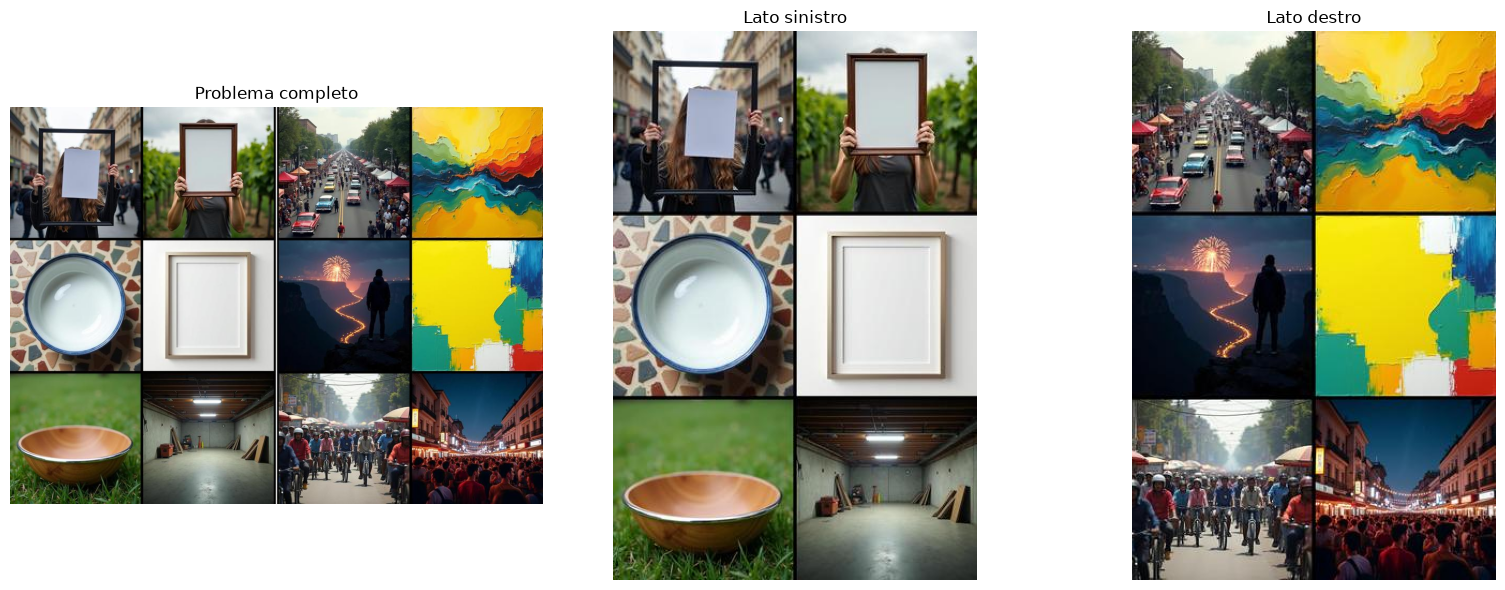

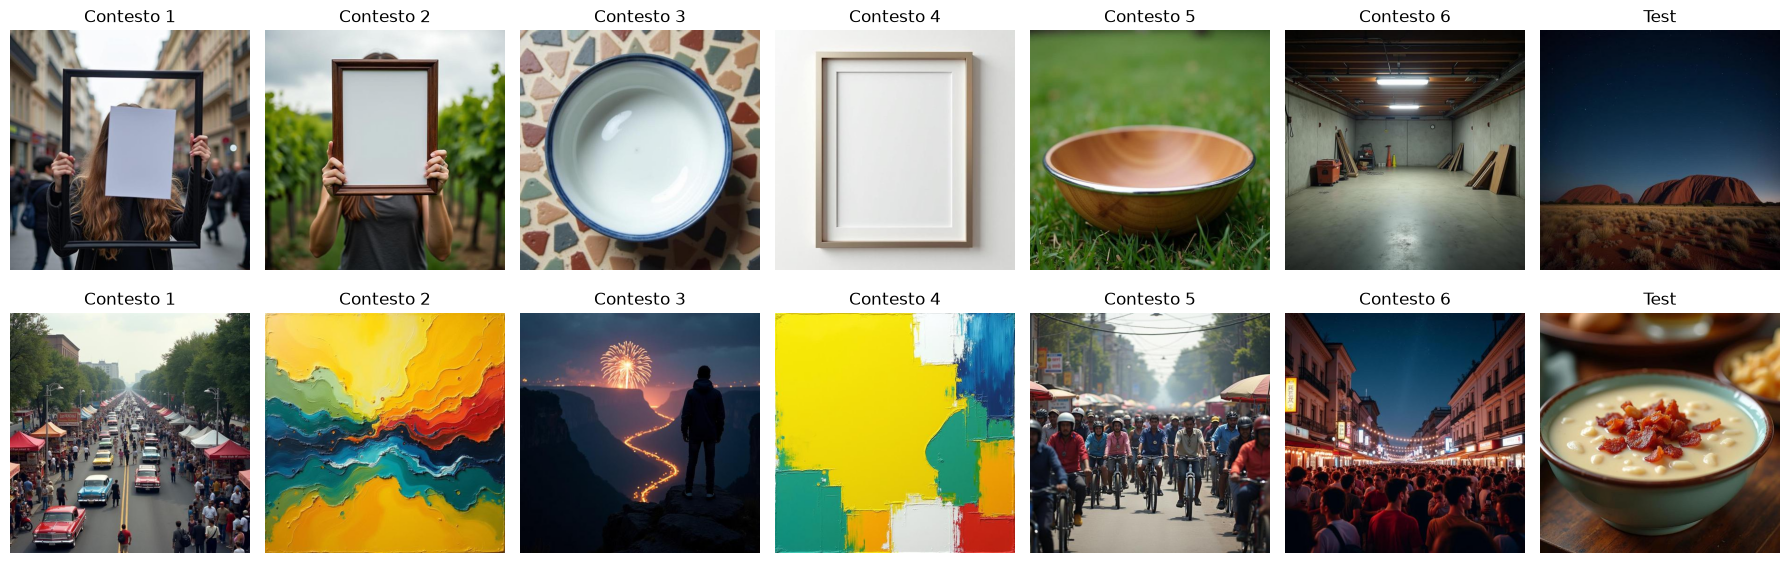

In [66]:
#visualizziamo un problema Bongard completo e le immagini che lo compongono

record_idx = 0
record = rwr_records[record_idx]

#mostriamo le informazioni del problema
print(f"ID: {record['id']}")
print(f"Gruppo: {record['concept_group']}")
print(f"Sinistra: {record['left_concept']}")
print(f"Destra: {record['right_concept']}")
print(f"Diversity: {record['diversity']}")

#visualizziamo le tre rappresentazioni aggregate
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, key, title in zip(
    axes,
    ["whole_image", "left_side_image", "right_side_image"],
    ["Problema completo", "Lato sinistro", "Lato destro"]
):
    img = Image.open(rwr_root / record[key])
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

#visualizziamo le sei immagini di contesto e l'immagine di test

record_idx = 0
record = rwr_records[record_idx]

fig, axes = plt.subplots(2, 7, figsize=(18, 6))

for row, side in enumerate(["left", "right"]):

    images = record[f"{side}_images"]

    for i, image_path in enumerate(images):

        img = Image.open(rwr_root / image_path)

        axes[row, i].imshow(img)

        #le prime sei immagini costituiscono il contesto
        if i < 6:
            axes[row, i].set_title(f"Contesto {i+1}")
        else:
            axes[row, i].set_title("Test")

        axes[row, i].axis("off")

    axes[row, 0].set_ylabel(
        f"{side.upper()}\n{record[f'{side}_concept']}",
        fontsize=11
    )

plt.tight_layout()
plt.show()

### Analisi della diversità

DIVERSITY GENERALE


,diversity
count,5400.000000
mean,0.185875
std,0.079921
min,0.029000
25%,0.125000
50%,0.180000
75%,0.244250
max,0.410000



DIVERSITY PER GRUPPO CONCETTUALE


,count,mean,std,min,median,max,nunique
concept_group,,,,,,,
Position,1300,0.222,0.081,0.034,0.213,0.410,140
Similarity,500,0.203,0.077,0.050,0.208,0.402,68
Size,400,0.187,0.076,0.051,0.177,0.367,65
Rotation,500,0.185,0.083,0.029,0.193,0.392,73
Count,800,0.182,0.067,0.046,0.179,0.366,96
Angle,400,0.168,0.068,0.055,0.156,0.348,63
Contour,400,0.164,0.092,0.033,0.157,0.336,53
Branching,200,0.162,0.048,0.088,0.160,0.252,28
Shape,900,0.150,0.071,0.033,0.146,0.350,105



DIVERSITY PER COPPIA DI CONCETTI


count  \
concept_group left_concept                                       right_concept                                               
Position      Three points on a straight line                    No three points on a straight line                    100   
              Two circles close to each other                    No two circles close to each other                    100   
              Points inside the figure outline are on a strai... Points inside the figure outline are not on a s...    100   
              Triangle inside of the circle                      Circle inside of the triangle                         100   
              Outline circles on one straight line               Outline circles not on one straight line              100   
Shape         Triangles                                          Circles                                               100   
Similarity    Identical figures                                  Figures not identical                                 100   
              Three identical elements                           Four identical elements                               100   
Rotation      Arrows pointing in different directions            Arrows pointing in the same direction                 100   
Count         More solid black circles                           More outline circles                                  100   
Rotation      An acute angle directed inward                     No angle directed inward                              100   
Position      Axes of symmetry                                   No axes of symmetry                                   100   
Rotation      Vertical hatched lines                             Horizontal hatched lines                              100   
Count         One line                                           Two lines                                             100   
Size          A large hole                                       A small hole                                          100   
Contour       Smooth contour figures                             Twisting contour figures                              100   
Position      Triangle above circle                              Circle above triangle                                 200   
Contour       Outline figures                                    Solid figures                                         100   
Similarity    All figures of the same color                      Figures of different colors                           100   
Position      Ends of the curve are parallel                     Ends of the curve are perpendicular                   100   
Count         Four parts                                         Five parts                                            100   
Similarity    Figures are similar                                Figures are not similar                               100   
Size          Large figures                                      Small figures                                         100   
Angle         Convex figures                                     Nonconvex figures                                     100   
Position      Segments almost parallel to each other             Large angles between segments                         100   
Count         Three parts                                        Four parts                                            100   
              One figure                                         Two figures                                           100   
Size          Small figure present                               No small figure present                               100   
Branching     The chain does not branch                          The chain branches                                    100   
Angle         Long sides concave                                 Long sides convex                                     100   
Count         Empty picture                                      Not empty picture   

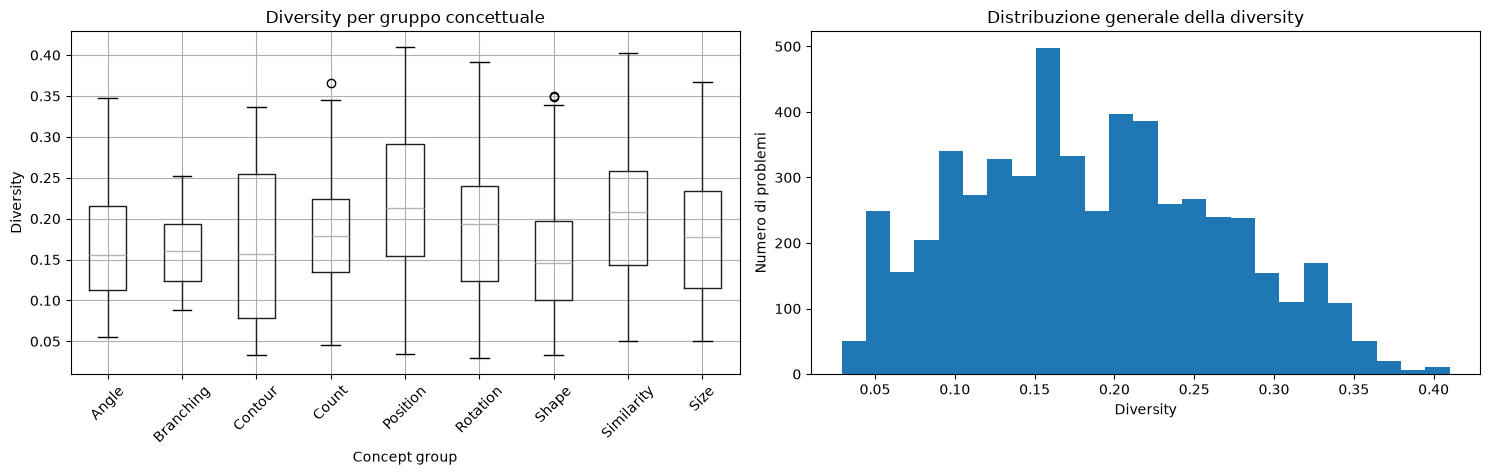

In [76]:
#analizziamo la distribuzione della diversity

rwr_df["diversity"] = pd.to_numeric(rwr_df["diversity"], errors="coerce")

#statistiche generali
print("DIVERSITY GENERALE")
display(rwr_df["diversity"].describe().to_frame())

#statistiche per gruppo concettuale
print("\nDIVERSITY PER GRUPPO CONCETTUALE")

diversity_group = rwr_df.groupby("concept_group")["diversity"].agg(
    ["count", "mean", "std", "min", "median", "max", "nunique"]
).sort_values("mean", ascending=False)

display(diversity_group.round(3))

#statistiche per coppia di concetti
print("\nDIVERSITY PER COPPIA DI CONCETTI")

diversity_pair = rwr_df.groupby(
    ["concept_group", "left_concept", "right_concept"]
)["diversity"].agg(
    ["count", "mean", "std", "min", "max", "nunique"]
).sort_values("mean", ascending=False)

display(diversity_pair.round(3))

#visualizziamo la distribuzione per gruppo
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

rwr_df.boxplot(
    column="diversity",
    by="concept_group",
    ax=axes[0],
    rot=45
)

axes[0].set_title("Diversity per gruppo concettuale")
axes[0].set_xlabel("Concept group")
axes[0].set_ylabel("Diversity")

axes[1].hist(rwr_df["diversity"].dropna(), bins=25)
axes[1].set_title("Distribuzione generale della diversity")
axes[1].set_xlabel("Diversity")
axes[1].set_ylabel("Numero di problemi")

plt.suptitle("")
plt.tight_layout()
plt.show()

Questi risultati mostrano che la varietà visiva non è uniforme all'interno del benchmark e può variare sensibilmente in funzione del concetto rappresentato. Tale caratteristica sarà importante da considerare nelle successive valutazioni dei VLM, poiché potrebbe influenzarne le prestazioni.